## <font color=#0099CC>mIAx - Taller Renta Fija - ANÁLISIS CARTERA DE RENTA FIJA</font>

En esta práctica, desarrollaremos un análisis exahustivo de un universo de Renta Fija, en concreto, de bonos corporativos. Además, construiremos y analizaremos varias carteras. 

Para ello, contaremos con la siguiente información almacenada en la carpeta *data*:
- **Universo de bonos**, con sus características esenciales (fichero *universo.csv*)
- **Histórico de precios** de cierre del universo de bonos anterior (fichero *precios_historicos_universo.csv*)
- **Curva de tipos de interés €STR** (fichero *curvaESTR.csv*)
- **Histórico de precios de otros índices** que nos serán de utilidad (fichero *precios_historicos_varios.csv*):
    - Índices de crédito: ITRAXX Main y ITRAXX XOVER. Serán útiles para la cobertura del riesgo de crédito.
    - Futuros sobre el *Schatz* (DU1), *BOBL* (OE1) y *BUND* (RX1). Serán útiles para la cobertura de los tipos de interés.
    - Índice de crédito *RECMTREU*, que valdría como benchmark de las carteras que construyamos.

No necesariamente se usará toda toda la información.

📣 <font color=#CC6600>**¡NORMAS!**</font>

La práctica se puede hacer en grupos de hasta **3 personas** y deberá entregarse antes del **26 de noviembre**. 

**ENTREGABLES**: 
* **Carpeta .zip** con el nombre del capitán del grupo.
* La carpeta debe mantener la estructura original.
* Los ficheros **funciones_aux.py** y **analisis_cartera.ipynb** deben completarse según se considere. 
* Deberán ser ejecutables y **enviarse ya debidamente ejecutados** y con los **resultados guardados**.
* Todo el **código debe estar comentado y razonado.**
* Las **celdas de texto deben responder explícitamente a las preguntas realizadas.**
* En la subcarpeta **"results" deberán estar los ficheros .csv** que se piden en los diferentes apartados.

Cada grupo expondrá una parte de los ejercicios en la clase del día 26, donde la resolveremos juntos a modo de taller. Esta exposición contará hasta **1 punto** de la nota final.
Cada apartado de esta práctica también contará hasta **1 punto** de la nota final.

Además, se valorará positivamente para la práctica la participación en las clases.

📣 <font color=#CC6600>**¡IMPORTANTE!**</font>

Todo el código implementado debe estar debidamente comentado e incluir conclusiones de los resultados obtenidos para optar a la máxima puntuación. Asimismo, se debe responder a las preguntas planteadas.

Las propuestas de mejora o posibles trabajos futuros se valorarán positivamente también.

Usa las fuentes de información que consideres necesarias para apoyar tus respuestas.

### <font color=#336699>Librerías</font>

In [1]:
import datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Estilo de los gráficos
plt.style.use('dark_background')

# Fecha de análisis: todas las valoraciones del trabajo se hacen a este día
fecha_analisis = pd.to_datetime('2026-10-01')

# El notebook está en src/ y los datos en ../data/
RUTA_DATOS = '../data/'
RUTA_RESULTS = '../results/'


In [2]:
# Recarga automáticamente funciones_aux.py cada vez que lo modifiquemos
%load_ext autoreload
%autoreload 2

# Importamos nuestras funciones auxiliares con el alias 'fa'
import funciones_aux as fa

### <font color=#336699>1. Datos</font>

**Análisis de datos.** En esta sección, haremos un análisis de la información que tenemos de cada bono y lo que significa. Asimismo, haremos los tratamientos y limpieza que necesitemos para luego poder usarlos.

Haz un primer análisis visual de la información que tenemos del universo de bono.
Entre otras, plantéate cuestiones como:
- ¿Divisas?
- ¿Tipo de bonos? ¿Fijo/Flotante? ¿Prelación? ¿Opcionalidad? ¿Hay bonos perpetuos?
- ¿Sectores? ¿Emisores? Si invirtéramos en todos los bonos, ¿dirías a priori que la cartera está diversificada?
- ¿Ratings? (Riesgo de crédito)
- ¿Otros datos cuantitativos?
    - Riesgo de liquidez - Horquillas y nominal vivo
- ¿Hay *gaps* en la información que vamos a tener que tratar?

**Guarda en "results" dos ficheros .csv:
1. "control_calidad_universo.csv" generado con la infomación del fichero universo.csv y que contenga las siguientes columnas para cada característica de los bonos:**
- número de observaciones
- número de datos *missing*
- número de valores únicos
- mínimo y máximo si aplica

2. "control_calidad_precios.csv" generado con la infomación del fichero precios_historicos_universo.csv y que para cada bono contenga las siguientes columnas:
- número de observaciones
- número de datos *missing*
- mínimo y máximo
- fecha inicio y fecha fin de cotización

Saca conclusiones de estas tablas de control. Identifica al menos 2 posibles problemas de calidad en estos dos ficheros que puedan afectar a los cálculos posteriores. Para cada uno, indica:
- problema
- tratamiento propuesto
- número de bonos afectados
- consecuencia de no tratarlo

In [3]:
# Cargamos el universo de bonos
universo = pd.read_csv(
    RUTA_DATOS + 'universo.csv',
    sep=';',                    # el fichero usa ; como separador
    encoding='utf-8-sig',       # elimina el carácter BOM invisible del inicio del fichero
    na_values=['#N/A N/A']      # marcador de "sin dato" de Bloomberg -> NaN
)

# Convertimos las columnas de fecha de texto (dd/mm/aaaa) a fechas reales
cols_fecha = ['Maturity', 'Next Call Date', 'First Coupon Date',
              'Penultimate Coupon Date', 'Issue date']
for col in cols_fecha:
    universo[col] = pd.to_datetime(universo[col], format='%d/%m/%Y')

# Usamos el ISIN como índice: es el identificador único de cada bono
universo = universo.set_index('ISIN')

# Primer vistazo: tipos de cada columna y valores no nulos
universo.info()
universo.head()

<class 'pandas.DataFrame'>
Index: 2165 entries, XS0161488498 to XS2694995163
Data columns (total 20 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   Description              2165 non-null   str           
 1   Ccy                      2165 non-null   str           
 2   Price                    2165 non-null   float64       
 3   Issuer                   2165 non-null   str           
 4   Industry Sector          2165 non-null   str           
 5   Maturity                 2147 non-null   datetime64[us]
 6   Coupon                   2165 non-null   float64       
 7   Rating                   2162 non-null   str           
 8   PD 1YR                   2142 non-null   float64       
 9   Outstanding Amount       2165 non-null   int64         
 10  Callable                 2165 non-null   str           
 11  Next Call Date           1582 non-null   datetime64[us]
 12  Seniority                2165 n

,Description,Ccy,Price,Issuer,Industry Sector,Maturity,Coupon,Rating,PD 1YR,Outstanding Amount,Callable,Next Call Date,Seniority,Coupon Frequency,Coupon Type,First Coupon Date,Penultimate Coupon Date,Issue date,Bid Price,Ask Price
ISIN,,,,,,,,,,,,,,,,,,,,
XS0161488498,DT 7 ½ 01/24/33,EUR,117.8740,DEUTSCHE TELEKOM INT FIN,Communications,2033-01-24,7.500,BBB+,0.021966,500000000,N,NaT,Sr Unsecured,1,FIXED,2004-01-24,2032-01-24,2003-01-24,117.6614,118.0866
FR0000471930,ORAFP 8 ⅛ 01/28/33,EUR,121.4000,ORANGE SA,Communications,2033-01-28,8.125,BBB+,0.000021,1500000000,N,NaT,Sr Unsecured,1,FIXED,2004-01-28,2032-01-28,2003-01-28,121.1417,121.6583
XS0162513211,EOANGR 5 ¾ 02/14/33,EUR,108.3925,E.ON INTL FINANCE BV,Utilities,2033-02-14,5.750,BBB+,0.000101,600000000,N,NaT,Sr Unsecured,1,FIXED,2004-02-14,2032-02-14,2003-02-14,108.1680,108.6170
XS0162869076,TELEFO 5 ⅞ 02/14/33,EUR,108.1155,TELEFONICA EUROPE BV,Communications,2033-02-14,5.875,BBB-,0.000125,500000000,N,NaT,Sr Unsecured,1,FIXED,2004-02-14,2032-02-14,2003-02-14,107.8141,108.4169
FR0010014845,PEUGOT 6 09/19/33,EUR,102.0467,PSA TRESORERIE GIE,"Consumer, Cyclical",2033-09-19,6.000,BBB,0.024240,600000000,N,NaT,Sr Unsecured,1,FIXED,2004-09-19,2032-09-19,2003-09-19,101.6177,102.4757


In [4]:
import os

# Control de calidad del universo con las columnas ORIGINALES del fichero
# (leemos solo la cabecera del CSV, nrows=0, para no depender de las columnas
#  que añadimos después en el notebook)
cols_fichero = pd.read_csv(RUTA_DATOS + 'universo.csv', sep=';',
                           encoding='utf-8-sig', nrows=0).columns
cc_universo = fa.control_calidad_universo(universo.reset_index()[cols_fichero])

os.makedirs(RUTA_RESULTS, exist_ok=True)
cc_universo.to_csv(RUTA_RESULTS + 'control_calidad_universo.csv', sep=';')
cc_universo

,NumObservaciones,NumMissing,NumValoresUnicos,Minimo,Maximo
Caracteristica,,,,,
ISIN,2165,0,2165,NaN,NaN
Description,2165,0,2163,NaN,NaN
Ccy,2165,0,1,NaN,NaN
Price,2165,0,2164,43.1028,121.4
Issuer,2165,0,605,NaN,NaN
Industry Sector,2165,0,9,NaN,NaN
Maturity,2147,18,1438,2026-12-04 00:00:00,2083-06-30 00:00:00
Coupon,2165,0,314,0.0,9.875
Rating,2162,3,12,NaN,NaN


Tabla de control de calidad del universo: **una fila por cada una de las 21 columnas originales** del fichero (ISIN y 20 características), con nº de observaciones, *missing*, valores únicos y mínimo/máximo. Se genera antes de añadir columnas propias y se guarda en `results/control_calidad_universo.csv`. Las conclusiones del control de calidad están en el apartado *Precios bonos universo*.

#### <font color=#808080>Divisas</font>

In [5]:
# Número de bonos por divisa
universo['Ccy'].value_counts()

Ccy
EUR    2165
Name: count, dtype: int64

Los 2.165 bonos están en **EUR**. Esto tiene dos ventajas: no hay **riesgo de divisa** en la cartera, y podemos valorar todos los bonos con **una única curva de descuento en euros (€STR)**, ya que los flujos deben descontarse con tipos de interés de su misma divisa. Si hubiera bonos en otras divisas (p. ej. USD), necesitaríamos su propia curva (p. ej. SOFR) o convertir sus flujos a euros.

#### <font color=#808080>Tipos de bono</font>

In [6]:
# Tipo de cupón: fijo o variable
print(universo['Coupon Type'].value_counts(), '\n')

# Prelación (orden de cobro en caso de impago)
print(universo['Seniority'].value_counts(), '\n')

# Opcionalidad: ¿el emisor puede amortizar anticipadamente?
print(universo['Callable'].value_counts(), '\n')

# Bonos perpetuos = bonos sin fecha de vencimiento
perpetuos = universo[universo['Maturity'].isna()]
print(f'Número de bonos perpetuos: {len(perpetuos)}')
perpetuos[['Description', 'Seniority', 'Coupon Type', 'Next Call Date']]

Coupon Type
FIXED       1835
VARIABLE     330
Name: count, dtype: int64 

Seniority
Sr Unsecured        1614
Sr Non Preferred     182
Sr Preferred         165
Subordinated         147
Jr Subordinated       24
Secured               20
1st lien              13
Name: count, dtype: int64 

Callable
Y    1582
N     583
Name: count, dtype: int64 

Número de bonos perpetuos: 18


,Description,Seniority,Coupon Type,Next Call Date
ISIN,,,,
XS1206541366,VW 3 ½ PERP,Jr Subordinated,VARIABLE,2030-03-20
XS1492580516,SLHNVX 4 ½ PERP,Subordinated,VARIABLE,2027-05-19
XS1629774230,VW 3 ⅞ PERP,Jr Subordinated,VARIABLE,2027-06-14
XS1799939027,VW 4 ⅝ PERP,Jr Subordinated,VARIABLE,2028-06-27
FR0013447877,ORAFP 1 ¾ PERP,Jr Subordinated,VARIABLE,2026-12-19
XS2056730679,IFXGR 3 ⅝ PERP,Jr Subordinated,VARIABLE,2028-01-01
XS2187689380,VW 3 ⅞ PERP,Jr Subordinated,VARIABLE,2029-06-17
XS2195190520,SSELN 3 ⅛ PERP,Jr Subordinated,VARIABLE,2027-04-14
FR00140005L7,ORAFP 1 ¾ PERP,Jr Subordinated,VARIABLE,2028-07-15


- 1.835 bonos (85%) son de **cupón fijo** y 330 **variables**. Los 330 variables son híbridos *fixed-to-floating*: **todos tienen call** y 309 son de **emisores financieros** (bancos y aseguradoras), que los emiten porque computan como capital regulatorio. Si el emisor no ejerce la call, el cupón pasa a flotante.
- Predomina la deuda **Sr Unsecured** (1.614; 75%). Hay 171 bonos subordinados (147 Subordinated + 24 Jr Subordinated) y deuda bancaria Sr Preferred (165) y Sr Non Preferred (182).
- 1.582 bonos (73%) son **callable**, y en 11 la fecha call ya ha pasado.
- Hay **18 perpetuos**, todos subordinados y con cupón variable. Al no tener vencimiento, los valoramos a su **próxima fecha call** (según el enunciado); el único con la call ya pasada (BNFP 1 PERP) se valora a su próximo cupón (16/12/2026).

#### <font color=#808080>Sectores y emisores</font>

In [7]:
# Número y porcentaje de bonos por sector
sectores = pd.DataFrame({
    'Nº bonos': universo['Industry Sector'].value_counts(),
    '% bonos': (universo['Industry Sector'].value_counts(normalize=True) * 100).round(1)
})
sectores

,Nº bonos,% bonos
Industry Sector,,
Financial,969,44.8
"Consumer, Non-cyclical",391,18.1
Industrial,199,9.2
Communications,168,7.8
"Consumer, Cyclical",165,7.6
Utilities,146,6.7
Basic Materials,65,3.0
Technology,49,2.3
Energy,13,0.6


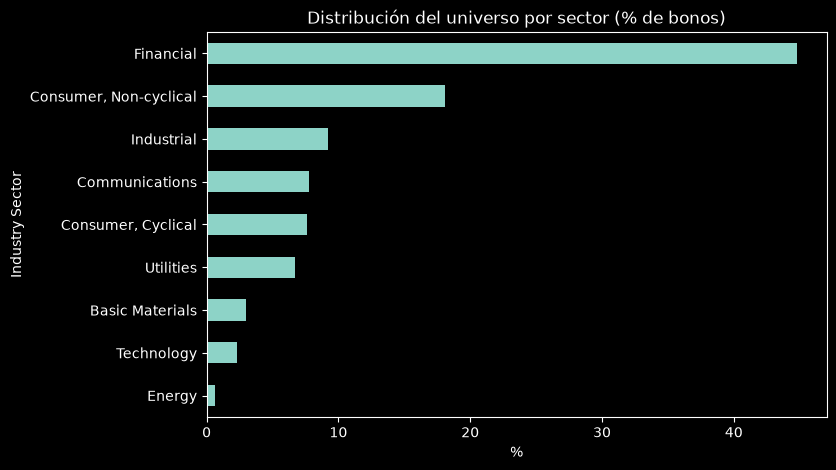

In [8]:
# Gráfico de barras horizontal por sector
sectores['% bonos'].sort_values().plot(kind='barh', figsize=(8, 5))
plt.title('Distribución del universo por sector (% de bonos)')
plt.xlabel('%')
plt.show()

El universo está muy **concentrado en el sector financiero (44,8%)**, seguido de consumo no cíclico (18,1%), industrial (9,2%), comunicaciones (7,8%) y consumo cíclico (7,6%). Energía (0,6%) y tecnología (2,3%) apenas aparecen. Una cartera con todo el universo **no estaría diversificada sectorialmente**: casi la mitad dependería del ciclo bancario y de la regulación financiera, y un shock en el sector (p. ej. una crisis bancaria) afectaría a gran parte de la cartera a la vez.

In [9]:
# Agrupamos por emisor: nº de bonos y nominal vivo total
emisores = universo.groupby('Issuer').agg(
    n_bonos=('Description', 'count'),
    nominal_total=('Outstanding Amount', 'sum')
)

# Peso de cada emisor en una cartera equiponderada (todos los bonos con el mismo peso)
emisores['% cartera_eq'] = (emisores['n_bonos'] / len(universo) * 100).round(2)

print(f'Número de emisores: {len(emisores)}')
emisores.sort_values('n_bonos', ascending=False).head(15)

Número de emisores: 605


,n_bonos,nominal_total,% cartera_eq
Issuer,,,
BANQUE FED CRED MUTUEL,32,32104000000,1.48
BNP PARIBAS,25,30928000000,1.15
BPCE SA,23,21250000000,1.06
ORANGE SA,22,17350000000,1.02
VOLKSWAGEN INTL FIN NV,21,23050000000,0.97
VONOVIA SE,21,14327800000,0.97
SOCIETE GENERALE,21,22250000000,0.97
NESTLE FINANCE INTL LTD,20,13450000000,0.92
CREDIT AGRICOLE SA,19,21500000000,0.88


In [10]:
# Concentración: peso de los 10 emisores con más bonos
top10 = emisores['n_bonos'].nlargest(10).sum() / len(universo) * 100
print(f'Los 10 mayores emisores suponen el {top10:.1f}% del universo')

Los 10 mayores emisores suponen el 10.3% del universo


Hay **605 emisores** (204 de ellos con un solo bono). Los mayores son bancos franceses (BFCM 32 bonos, BNP Paribas 25, BPCE 23, Société Générale 21), además de Orange (22), Volkswagen (21) y Vonovia (21). Los 10 mayores suman el **10,3%** del universo; en una cartera equiponderada, el mayor emisor (BFCM) pesaría un 1,5%.

**¿Está diversificada?** Por número de emisores, sí: ningún emisor tiene un peso relevante por sí solo. Pero, junto con el peso del sector financiero (44,8%), hay una **concentración relevante en banca francesa**, cuyos bonos tienden a moverse juntos ante noticias del sector o del riesgo país de Francia.

#### <font color=#808080>Ratings (Riesgo de crédito)</font>

Rating
AAA       4.0
AA+       6.0
AA       20.0
AA-      96.0
A+      180.0
A       222.0
A-      363.0
BBB+    415.0
BBB     300.0
BBB-    176.0
BB+       8.0
NR      372.0
Name: count, dtype: float64
Bonos sin dato de rating (NaN): 3


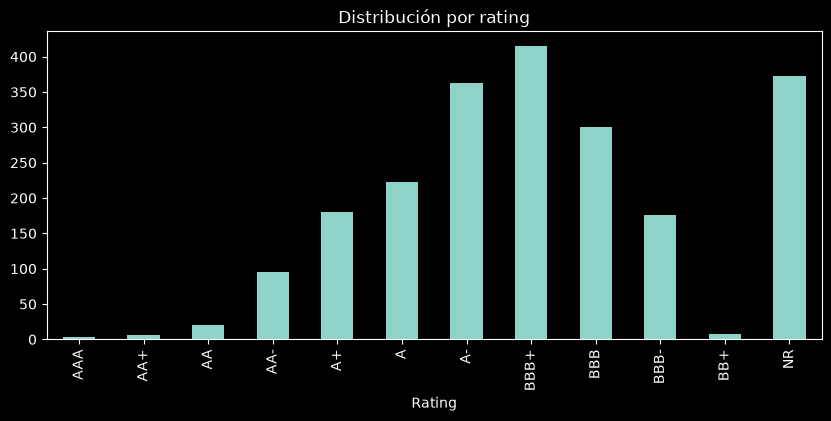

In [11]:
# Escala de ratings de mejor a peor, para ordenar las tablas y gráficos
escala = ['AAA', 'AA+', 'AA', 'AA-', 'A+', 'A', 'A-',
          'BBB+', 'BBB', 'BBB-',                    # hasta aquí: Investment Grade
          'BB+', 'BB', 'BB-', 'B+', 'B', 'B-',      # High Yield
          'NR']                                      # sin rating

# Nº de bonos por rating en el orden de la escala (eliminamos los que no aparecen)
ratings = universo['Rating'].value_counts().reindex(escala).dropna()
print(ratings)
print(f"Bonos sin dato de rating (NaN): {universo['Rating'].isna().sum()}")

ratings.plot(kind='bar', figsize=(10, 4))
plt.title('Distribución por rating')
plt.show()

In [12]:
# Clasificamos cada bono en IG / HY / Sin rating
grado_inversion = escala[:10]   # de AAA a BBB-

def clasificar_rating(rating):
    """Devuelve 'IG', 'HY' o 'Sin rating' según el rating del bono."""
    if pd.isna(rating) or rating == 'NR':
        return 'Sin rating'
    return 'IG' if rating in grado_inversion else 'HY'

universo['Categoria'] = universo['Rating'].apply(clasificar_rating)
universo['Categoria'].value_counts()

Categoria
IG            1782
Sin rating     375
HY               8
Name: count, dtype: int64

In [13]:
# ¿Qué probabilidad de impago a 1 año tiene cada categoría?
universo.groupby('Categoria')['PD 1YR'].describe()


,count,mean,std,min,25%,50%,75%,max
Categoria,,,,,,,,
HY,8.0,0.007917,0.010345,2.872080e-06,0.000026,0.001057,0.020395,0.020395
IG,1765.0,0.003777,0.008857,2.944640e-12,0.000014,0.000118,0.001036,0.063122
Sin rating,369.0,0.002893,0.005606,1.082270e-09,0.000015,0.000298,0.002114,0.031020


In [14]:
# ¿De qué sectores son los bonos sin rating?
sin_rating = universo[universo['Categoria'] == 'Sin rating']
print(sin_rating['Industry Sector'].value_counts())
print(f"Financieros: {(sin_rating['Industry Sector'] == 'Financial').mean() * 100:.1f}%")

Industry Sector
Financial                 189
Industrial                 45
Consumer, Non-cyclical     43
Utilities                  38
Consumer, Cyclical         15
Technology                 15
Basic Materials            11
Communications             10
Energy                      9
Name: count, dtype: int64
Financieros: 50.4%


- El universo es casi todo **Investment Grade** (1.782 bonos; 82%); los ratings más frecuentes son BBB+ (415) y A- (363). La calidad crediticia media es buena, pero el grueso está en la parte baja del IG (BBB+ a BBB-: 891 bonos), donde una rebaja de rating puede llevar al bono a HY.
- Solo hay **8 bonos High Yield**, todos BB+ (el mejor escalón HY).
- Hay **375 bonos sin rating** (372 NR + 3 sin dato), la mitad de ellos financieros.
- La PD mediana a 1 año de los sin rating (0,000298) está **entre la de los IG (0,000118) y la de los HY (0,001057)**, en las unidades del fichero: su riesgo de impago estimado es algo mayor que el de los IG, pero muy inferior al de los HY. Usamos la mediana en lugar de la media porque la PD tiene valores extremos que distorsionan la media (en IG, media 0,003777 vs mediana 0,000118).
- **Decisión:** por prudencia, en el mandato **tratamos los sin rating como HY**, ya que no podemos verificar su calidad crediticia y así nunca incumpliríamos el límite del 10% en HY.

#### <font color=#808080>Riesgo de liquidez - Horquillas y nominal vivo</font>

In [15]:
# Horquilla bid-ask en puntos de precio
universo['Horquilla'] = universo['Ask Price'] - universo['Bid Price']

# Nominal vivo en millones, más fácil de leer
universo['Nominal_mill'] = universo['Outstanding Amount'] / 1e6

universo[['Horquilla', 'Nominal_mill']].describe()

,Horquilla,Nominal_mill
count,2165.000000,2165.000000
mean,0.235440,744.580655
std,0.145767,308.231911
min,0.029200,250.003000
25%,0.129300,500.000000
50%,0.201900,700.000000
75%,0.307590,1000.000000
max,1.537550,3000.000000


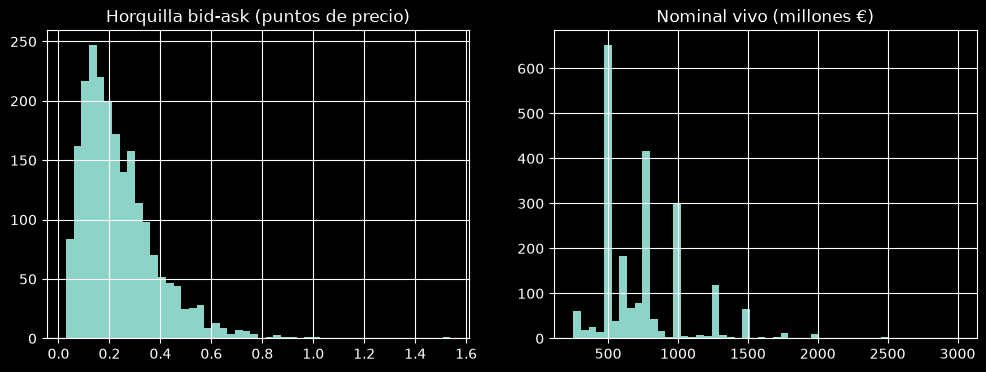

In [16]:
# Histogramas de horquilla y nominal vivo
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

universo['Horquilla'].hist(bins=50, ax=ax[0])
ax[0].set_title('Horquilla bid-ask (puntos de precio)')

universo['Nominal_mill'].hist(bins=50, ax=ax[1])
ax[1].set_title('Nominal vivo (millones €)')

plt.show()

In [17]:
# Horquilla mediana por categoría de rating
print(universo.groupby('Categoria')['Horquilla'].median(), '\n')

# Bonos excluidos por el mandato por tamaño (≤ 500 millones)
pequenos = (universo['Nominal_mill'] <= 500).sum()
print(f'Bonos con nominal ≤ 500M: {pequenos} ({pequenos / len(universo) * 100:.1f}%)')

Categoria
HY            0.12945
IG            0.19921
Sin rating    0.22599
Name: Horquilla, dtype: float64 

Bonos con nominal ≤ 500M: 767 (35.4%)


- Las horquillas bid-ask son **estrechas** (mediana ≈ 0,20 puntos, máximo 1,54), en línea con lo que suele observarse en crédito corporativo IG en euros. Como referencia, en la deuda pública alemana (*Bunds*), el mercado más líquido de la zona euro, la horquilla suele ser de solo **1–3 céntimos** (0,01–0,03 puntos), unas 10 veces menor: el crédito corporativo es líquido, pero bastante menos que la deuda soberana. El mínimo es positivo (0,03), así que no hay horquillas negativas: los datos de Bid y Ask son coherentes.
- Los bonos sin rating tienen una horquilla similar a los IG, lo que respalda que su liquidez no es peor. Los 8 HY no parecen menos líquidos, pero son demasiado pocos para concluir.
- El **35,4%** de las emisiones (767 bonos) tiene un nominal ≤ 500 millones y queda fuera del mandato: esta restricción reduce mucho el universo invertible antes de aplicar las demás.
- *Mejora propuesta:* medir la horquilla en pb de rentabilidad (horquilla / duración) en lugar de en puntos de precio. 0,20 puntos equivalen a ~20 pb de rentabilidad en un bono a 1 año, pero solo a ~2 pb en uno a 10 años, así que en puntos de precio los bonos largos parecen menos líquidos de lo que son. Podría calcularse con las duraciones de la sección 4.

#### <font color=#808080>Resto de información</font>

En esta sección, analizamos el resto de ficheros para ver qué información tenemos y, en caso de haber *gaps*, limpiar los datos antes de trabajar con ellos.

##### <font color=#CC6600>Precios bonos universo</font>

In [18]:
# Cargamos los precios históricos: filas = bonos, columnas = fechas
precios = pd.read_csv(
    RUTA_DATOS + 'precios_historicos_universo.csv',
    sep=';',
    index_col=0,             # la primera columna (identificador del bono) será el índice
    na_values=['#N/D'],      # marcador de "sin dato" -> NaN
    encoding='utf-8-sig'
)

# Transponemos: filas = fechas, columnas = bonos
precios = precios.T

# Convertimos el índice (texto) a fechas
precios.index = pd.to_datetime(precios.index, format='%d/%m/%Y')

# Los identificadores vienen como 'XS0161488498 Corp': nos quedamos solo con el ISIN
precios.columns = precios.columns.str.replace(' Corp', '', regex=False)

print(precios.shape)
print('¿Mismos bonos que en el universo?', set(precios.columns) == set(universo.index))

(1097, 2165)
¿Mismos bonos que en el universo? True


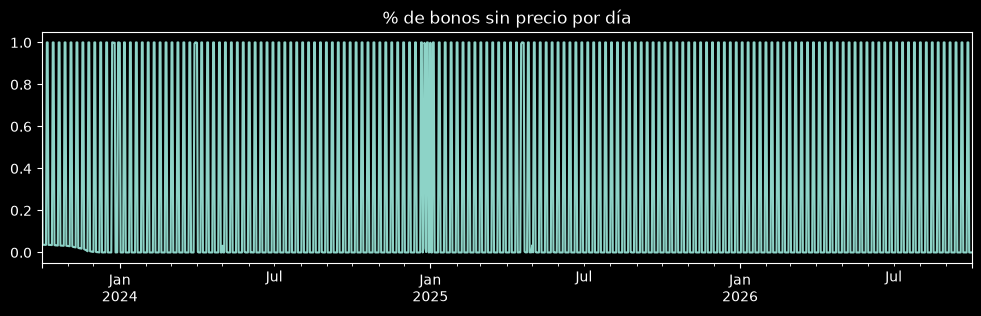

Días sin mercado: 323
De ellos, fines de semana: 313
Festivos entre semana: ['25/12/2023', '26/12/2023', '01/01/2024', '29/03/2024', '01/04/2024', '25/12/2024', '26/12/2024', '01/01/2025', '18/04/2025', '21/04/2025']


In [19]:
# Porcentaje de bonos sin precio en cada fecha
pct_nan_dia = precios.isna().mean(axis=1)

pct_nan_dia.plot(figsize=(12, 3))
plt.title('% de bonos sin precio por día')
plt.show()

# Días en los que (casi) ningún bono tiene precio: fines de semana y festivos
dias_sin_mercado = pct_nan_dia > 0.9
print(f'Días sin mercado: {dias_sin_mercado.sum()}')
print(f'De ellos, fines de semana: {(dias_sin_mercado & (precios.index.day_of_week >= 5)).sum()}')

# ¿Cuáles de esos días NO son fin de semana? (day_of_week: 0 = lunes ... 6 = domingo)
festivos = precios.index[dias_sin_mercado & (precios.index.day_of_week < 5)]
print('Festivos entre semana:', list(festivos.strftime('%d/%m/%Y')))

In [20]:
# Eliminamos fines de semana y festivos
precios = precios.loc[~dias_sin_mercado]
print(f'Días hábiles: {len(precios)}')

# ¿Qué bonos empiezan a cotizar más tarde? (emitidos después de oct-2023)
primer_precio = precios.apply(lambda serie: serie.first_valid_index())
emitidos_tarde = primer_precio[primer_precio > precios.index[0]]
print(f'Bonos que empiezan a cotizar después del inicio: {len(emitidos_tarde)}')

# Comprobamos que coinciden con su fecha de emisión
pd.DataFrame({
    'Primer precio': emitidos_tarde,
    'Fecha emisión': universo.loc[emitidos_tarde.index, 'Issue date']
}).head(10)

Días hábiles: 774
Bonos que empiezan a cotizar después del inicio: 79


,Primer precio,Fecha emisión
XS2698045130,2023-10-17,2023-09-29
XS2690050682,2023-10-06,2023-10-12
FR001400LCK1,2023-10-12,2023-10-18
XS2705604234,2023-10-13,2023-10-18
XS2698998593,2023-10-17,2023-10-23
XS2707169111,2023-10-17,2023-10-23
FR001400KSZ7,2023-10-18,2023-10-25
XS2704918478,2023-10-20,2023-10-25
XS2708354811,2023-10-19,2023-10-25
XS2661068234,2023-10-26,2023-10-30


In [21]:
# Control de calidad de los precios: tras quitar fines de semana y festivos
# (no son huecos de datos) y ANTES de rellenar huecos con ffill (que los ocultaría)
cc_precios = fa.control_calidad_precios(precios)
cc_precios.to_csv(RUTA_RESULTS + 'control_calidad_precios.csv', sep=';')

print(f"Bonos con algún missing: {(cc_precios['NumMissing'] > 0).sum()}")
print(f"Bonos con huecos entre cotizaciones: {(cc_precios['HuecosEntreCotizaciones'] > 0).sum()}")
print(f"Bonos que dejan de cotizar antes del final: {(cc_precios['FechaFin'] < precios.index[-1]).sum()}")
cc_precios.describe()

Bonos con algún missing: 222
Bonos con huecos entre cotizaciones: 147
Bonos que dejan de cotizar antes del final: 0


,NumObservaciones,NumMissing,Minimo,Maximo,FechaInicio,FechaFin,HuecosEntreCotizaciones
count,2165.000000,2165.000000,2165.000000,2165.000000,2165,2165,2165.000000
mean,772.727483,1.272517,87.054551,98.423157,2023-10-03 13:38:06.374134,2026-10-01 00:00:00,0.131178
min,723.000000,0.000000,42.695760,63.295000,2023-10-02 00:00:00,2026-10-01 00:00:00,0.000000
25%,774.000000,0.000000,80.873000,94.298000,2023-10-02 00:00:00,2026-10-01 00:00:00,0.000000
50%,774.000000,0.000000,88.004000,98.605320,2023-10-02 00:00:00,2026-10-01 00:00:00,0.000000
75%,774.000000,0.000000,95.402000,103.815000,2023-10-02 00:00:00,2026-10-01 00:00:00,0.000000
max,774.000000,51.000000,120.502000,240.270000,2023-12-08 00:00:00,2026-10-01 00:00:00,31.000000
std,6.250294,6.250294,9.829287,8.705512,NaN,NaN,0.855758


In [22]:
# Evidencias de los problemas de calidad detectados en los precios

# 1) Huecos entre cotizaciones: total y bono con más huecos
huecos = cc_precios['HuecosEntreCotizaciones']
print(f'Huecos totales: {huecos.sum()} | Bono con más huecos: {huecos.idxmax()} ({huecos.max()} días)')

# 2) Precio máximo anómalo: qué bono es y en qué fecha
isin_max = cc_precios['Maximo'].idxmax()
print(f"Precio máximo: {universo.loc[isin_max, 'Description']} ({isin_max}) = "
      f"{cc_precios.loc[isin_max, 'Maximo']} el {precios[isin_max].idxmax().date()}")

# 3) Saltos anómalos (spikes): variación diaria > 5% que revierte al día siguiente
rent_diaria = precios.ffill().pct_change(fill_method=None)
siguiente = rent_diaria.shift(-1)
spikes = (rent_diaria.abs() > 0.05) & (siguiente.abs() > 0.05) & (rent_diaria * siguiente < 0)
grandes = rent_diaria.abs() > 0.10
print(f'Saltos que revierten: {spikes.sum().sum()} en {(spikes.sum() > 0).sum()} bonos')
print(f'Movimientos diarios > 10%: {grandes.sum().sum()} en {(grandes.sum() > 0).sum()} bonos')

# 4) Precios anteriores a la fecha de emisión (mercado gris)
emision = universo.loc[precios.columns, 'Issue date']
antes_emision = precios.apply(
    lambda serie: serie.loc[:emision[serie.name] - pd.Timedelta(days=1)].notna().any()
)
print(f'Bonos con precios antes de su fecha de emisión: {antes_emision.sum()}')


# ¿Algún spike cae en una fecha de fin de mes (fechas de rebalanceo del backtest)?
fin_mes_cc = fa.fechas_fin_de_mes(precios.index)
print(f'Spikes en fechas de fin de mes: {spikes.loc[spikes.index.isin(fin_mes_cc)].sum().sum()}')

Huecos totales: 284 | Bono con más huecos: XS2698045130 (31 días)
Precio máximo: ALVGR 1 ⅜ 04/21/31 (DE000A180B80) = 240.27 el 2024-12-24
Saltos que revierten: 46 en 40 bonos
Movimientos diarios > 10%: 65 en 31 bonos
Bonos con precios antes de su fecha de emisión: 85
Spikes en fechas de fin de mes: 0


#### Control de calidad: conclusiones

**Universo (`control_calidad_universo.csv`).** 21 características y ISIN único (2.165 valores distintos). Solo hay *missing* en 5 columnas: `Next Call Date` (583: bonos no callable, es correcto), `PD 1YR` (23), `Maturity` y `Penultimate Coupon Date` (18: los perpetuos) y `Rating` (3). Todos los bonos están en EUR. `Description` tiene 2.163 valores únicos: hay dos pares de bonos distintos con la misma descripción, sin impacto porque identificamos por ISIN.

**Precios (`control_calidad_precios.csv`).** Tras quitar fines de semana y festivos quedan 774 días hábiles y ningún bono deja de cotizar antes del final. 222 bonos tienen algún *missing* (sobre todo por empezar a cotizar más tarde) y 147 tienen huecos reales entre cotizaciones (284 en total, máximo 31 días en XS2698045130). Las tablas de control se generan con los datos originales, antes de cualquier tratamiento.

**Problemas de calidad detectados:**

| Problema | Tratamiento | Bonos afectados | Consecuencia de no tratarlo |
|---|---|---|---|
| **Precios anómalos (*spikes*)**: saltos que revierten al día siguiente; p. ej. ALVGR 1⅜ 2031 pasa de ~91,7 a **240,27** el 24/12/2024 y vuelve a ~91,5 | **Aplicado:** marcamos como NaN los saltos > 5% que revierten al día siguiente y los rellenamos con el último precio válido (función `filtrar_spikes`) | 46 saltos en 40 bonos (65 movimientos diarios > 10% en 31 bonos) | Rentabilidades y volatilidades diarias falsas (p. ej. en coberturas o correlaciones). En el backtest mensual no hay impacto: ningún spike cae en un fin de mes (lo hemos comprobado) |
| **Precios anteriores a la fecha de emisión** (mercado gris) | **Aplicado:** en el backtest, cada bono cuenta solo desde su `Issue date` | 85 bonos | *Look-ahead bias*: la cartera "compraría" bonos que todavía no existían |
| **Huecos entre cotizaciones** | **Aplicado:** *forward fill*, manteniendo el último precio disponible | 147 bonos (284 días) | Rentabilidades NaN o bonos que entran y salen de la cartera; los precios "planos" infravaloran la volatilidad |
| **Ratings y PD ausentes**: 372 NR + 3 sin rating; 23 sin PD | **Decisión para la sección 6:** tratar los bonos sin rating como HY en el mandato (criterio prudente) | 375 sin rating; 23 sin PD | Podríamos incumplir el límite de HY del 10% y subestimar el riesgo de crédito |
| **Fechas call ya pasadas** (call ejercitable no ejercida) | **Aplicado:** valorar a vencimiento final; el perpetuo BNFP, al próximo cupón (función `fecha_vencimiento_efectiva`) | 11 bonos | Valorar a una fecha ya pasada y obtener z-spreads absurdos en bonos bajo la par |

In [23]:
# Tratamiento de los spikes: los marcamos como NaN para que el forward fill
# de la celda siguiente los sustituya por el último precio válido.
# (Las tablas de control de calidad ya se han generado con los datos originales.)
precios, spikes_detectados = fa.filtrar_spikes(precios)

print(f'Precios anómalos eliminados: {spikes_detectados.sum().sum()} '
      f'en {(spikes_detectados.sum() > 0).sum()} bonos')
print(f"Nuevo precio máximo de ALVGR 1⅜ 2031: {precios['DE000A180B80'].max()}")

Precios anómalos eliminados: 46 en 40 bonos
Nuevo precio máximo de ALVGR 1⅜ 2031: 94.172


Huecos rellenados: 330


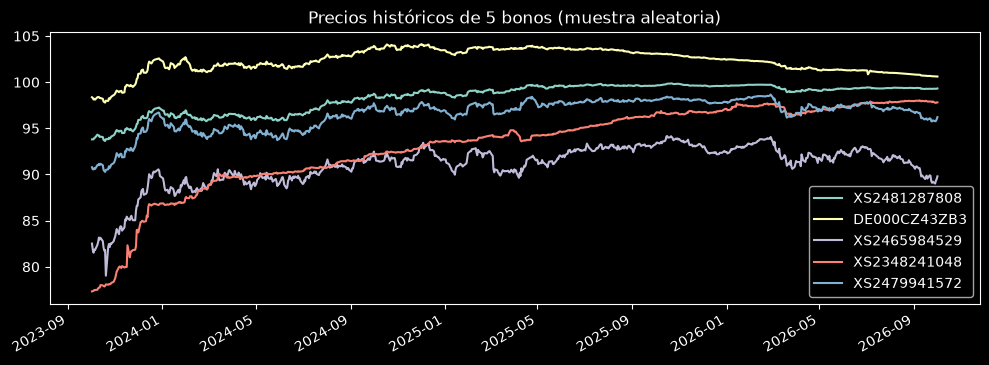

In [24]:
# Rellenamos los huecos puntuales con el último precio disponible
# (ffill no rellena los NaN iniciales: los bonos aún no emitidos siguen sin precio)
huecos_antes = precios.isna().sum().sum()
precios = precios.ffill()
print(f'Huecos rellenados: {huecos_antes - precios.isna().sum().sum()}')

# Evolución de precios de 5 bonos al azar (random_state fija la muestra)
precios.sample(5, axis=1, random_state=42).plot(figsize=(12, 4))
plt.title('Precios históricos de 5 bonos (muestra aleatoria)')
plt.show()

**Limpieza de precios.**
- Hay **323 días** sin precio para ningún bono: **313 fines de semana y 10 festivos** de mercado (Navidad, 26 de diciembre, Año Nuevo, Viernes Santo y Lunes de Pascua). No son huecos de datos, así que los eliminamos y quedan **774 días hábiles**.
- 79 bonos empiezan a cotizar más tarde por su fecha de emisión; sus NaN iniciales se mantienen (el *forward fill* no rellena hacia atrás).
- Antes del *forward fill* eliminamos los **46 spikes** detectados en el control de calidad (en 40 bonos), p. ej. el 240,27 de ALVGR 1⅜ 2031.
- El resto de huecos (284 días en 147 bonos) se rellenan con el **último precio disponible**, suponiendo que sin negociación el precio no cambia.
- Hemos comprobado, ejecutando el backtest con y sin el filtro de spikes, que **no altera sus resultados** (+15,32% la cartera y +12,74% el benchmark en ambos casos), ya que ningún spike cae en un fin de mes.

##### <font color=#CC6600>Otros precios</font>

Para terminar con el análisis de datos, falta lo leído en los ficheros de *precios_historicos_varios.csv* y *curvaESTR.csv*.

ITRX EUR CDSI GEN 5Y Corp      15
ITRX XOVER CDSI GEN 5Y Corp    15
DU1 Comdty                     12
OE1 Comdty                     12
RX1 Comdty                     12
RECMTREU Index                  0
dtype: int64
¿Mismas fechas que precios? False


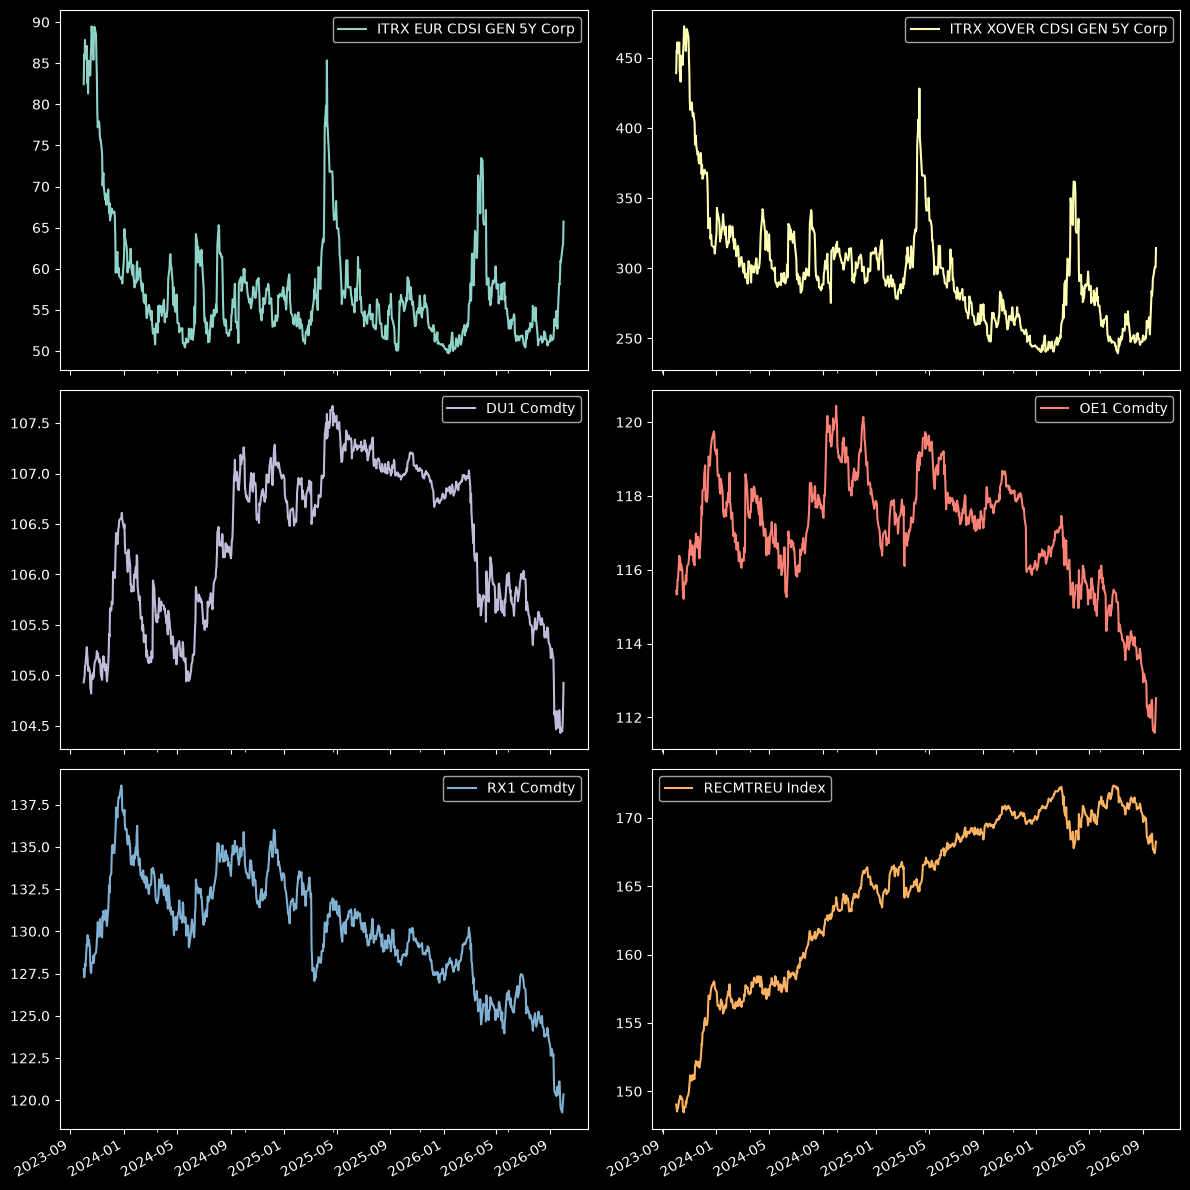

In [25]:
# Cargamos índices de crédito (iTraxx), futuros (DU1, OE1, RX1) y benchmark (RECMTREU)
varios = pd.read_csv(
    RUTA_DATOS + 'precios_historicos_varios.csv',
    sep=';', index_col=0, na_values=['#N/D'], encoding='utf-8-sig'
)
varios.index = pd.to_datetime(varios.index, format='%d/%m/%Y')

# Huecos por serie
print(varios.isna().sum())

# Rellenamos con el último valor disponible
varios = varios.ffill()

# ¿Las fechas coinciden con las de los precios de los bonos?
print('¿Mismas fechas que precios?', varios.index.equals(precios.index))

# Un gráfico por serie (escalas muy distintas)
varios.plot(subplots=True, figsize=(12, 12), layout=(3, 2))
plt.tight_layout()
plt.show()

Diferencia máxima: 6.765132900543591e-07


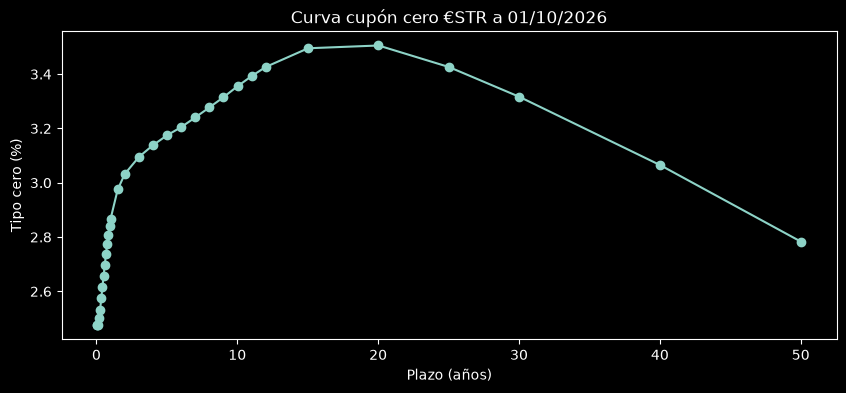

In [26]:
# Cargamos la curva €STR a 01/10/2026
curva = pd.read_csv(RUTA_DATOS + 'curvaESTR.csv', sep=';')
curva['Date'] = pd.to_datetime(curva['Date'], format='%d/%m/%Y')

# Plazo en años desde la fecha de análisis (base Act/365)
curva['Plazo'] = (curva['Date'] - fecha_analisis).dt.days / 365

# Comprobación: ¿el factor de descuento sale de capitalización continua?  DF = exp(-z·t)
curva['DF_check'] = np.exp(-curva['Zero Rate'] / 100 * curva['Plazo'])
print('Diferencia máxima:', (curva['DF_check'] - curva['Discount']).abs().max())

# Gráfico de la curva cero
curva.plot(x='Plazo', y='Zero Rate', marker='o', figsize=(10, 4), legend=False)
plt.title('Curva cupón cero €STR a 01/10/2026')
plt.xlabel('Plazo (años)')
plt.ylabel('Tipo cero (%)')
plt.show()

- **Índices y futuros:** pocos huecos (15 días en cada iTraxx y 12 en cada futuro), rellenados con el último valor disponible; el benchmark RECMTREU está completo. Las fechas coinciden con las de los precios de los bonos.
- **Curva €STR (33 nodos hasta 2076):** muy empinada en el tramo corto (del ~2,5% al ~3,0% en 1–2 años: el mercado descuenta subidas del €STR), sube suavemente hasta un máximo de ~3,5% en 15–20 años y **baja en el tramo muy largo** (~2,8% a 50 años), por la fuerte demanda de plazos largos de fondos de pensiones y aseguradoras para cubrir sus pasivos.
Los factores de descuento cumplen $DF = e^{-z \cdot t}$ con base ACT/365 (diferencia máxima ≈ $7 \cdot 10^{-7}$): la curva está en **capitalización continua**, y así la usamos para valorar.
- Como solo hay 33 plazos, necesitamos **interpolar** para descontar flujos en fechas intermedias (sección 2). La mayoría de nuestros bonos vence en menos de 15 años, en el tramo ascendente de la curva.

#### <font color=#808080>Conclusiones</font>

**Universo.** 2.165 bonos corporativos en EUR de 605 emisores, mayoritariamente de cupón fijo (85%) y deuda senior. El 73% son callable y hay 18 perpetuos (híbridos subordinados).

**Riesgos principales:**
- **Concentración:** el 44,8% del universo es del sector financiero, con un peso relevante de la banca francesa. Diversificado por número de emisores, pero no por sectores.
- **Crédito:** 82% Investment Grade, con el grueso en la parte baja (BBB+ a BBB-); solo 8 HY (BB+) y 375 bonos sin rating, que tratamos como HY por prudencia.
- **Liquidez:** horquillas estrechas (mediana ≈ 0,20 puntos); el 35,4% de las emisiones tiene un nominal ≤ 500M y queda fuera del mandato.

**Calidad de datos:** los datos son en general consistentes (ISIN único, una sola divisa, sin horquillas negativas), pero hemos detectado *spikes* en los precios, precios anteriores a la emisión, huecos de cotización, ratings y PD ausentes, y fechas call ya pasadas (ver tabla de control de calidad).

**Decisiones para el resto del trabajo:**
- **Precios:** eliminamos fines de semana y festivos (774 días hábiles), filtramos los 46 *spikes* y rellenamos los huecos con *forward fill*.
- **Backtest:** cada bono cuenta solo desde su fecha de emisión, para evitar *look-ahead bias*.
- **Valoración:** a la próxima fecha call (perpetuos incluidos). Si la call ya ha pasado, a vencimiento (el perpetuo BNFP, al próximo cupón).
- **Curva:** €STR en capitalización continua ACT/365, con interpolación exponencial de los factores de descuento.
- **Mandato:** los bonos sin rating cuentan como HY.

### <font color=#336699>2. Valoración</font>

**Valoración de los bonos del universo** utilizando la curva de descuento y bajo ciertas asunciones. Comparación de estos precios con los precios de mercado.

En esta sección, valoraremos los bonos utilizando la curva. Para ello, crea una función (puedes hacerlo en un .py aparte) que con las **características del bono, la curva y un spread de crédito** para que devuelva la valoración del bono (incluyendo **precio limpio, cupón corrido y precio sucio**).

Si asumimos que el **spread de crédito es 0**, y la ejecutamos para el 01/10/2026:
- ¿Qué observas si comparas los precios obtenidos y los precios de mercado? 
- ¿Crees que la diferencia se debe a un factor relacionado sólo con el riesgo crediticio?
- ¿Qué otros factores influyen en ese spread?

Para la valoración, haz las siguientes simplificaciones:

- Asume que el vencimiento de los bonos perpetuos (para los que no hay vencimiento) es la próxima fecha call.
- Asume que todos aquellos bonos que tengan call serán calleados. Por lo tanto, usa la fecha call como fecha de vencimiento.
- Asume que los cupones son fijos hasta vencimiento (aunque alguno cambie a lo largo de la vida del bono).
- Usa la base de cálculo ACT/365. No tengas en cuenta la convención de día hábil.

Ten en cuenta que necesitarás una función de interpolación también. Interpola los factores de descuento exponencialmente.

**Guarda en "results" una tabla llamada "valoracion.csv" que contenga:**

- ISIN
- PrecioMercado
- PrecioSucioCalculado
- CuponCorrido
- PrecioLimpioCalculado
- DiferenciaMecadoCalculo
- DiferenciaPct


In [23]:
# Establecemos la fecha
fecha_valor = datetime.datetime(2026,10,1)

In [24]:
# Convertimos la fecha de valoración al tipo de fecha de pandas
fecha_valor = pd.Timestamp(fecha_valor)

# Calculamos el vencimiento efectivo de cada bono (fila a fila: axis=1)
universo['Vto_efectivo'] = universo.apply(
    lambda bono: fa.fecha_vencimiento_efectiva(bono, fecha_valor), axis=1
)

# Comprobación: los 11 bonos con la fecha call ya pasada
call_pasada = universo['Next Call Date'] <= fecha_valor
universo.loc[call_pasada, ['Description', 'Next Call Date', 'Maturity', 'Vto_efectivo']]

,Description,Next Call Date,Maturity,Vto_efectivo
ISIN,,,,
XS1186176571,HTHROW 1 ½ 02/11/30,2026-02-11,2030-02-11,2030-02-11
XS1405762805,TKAAV 1 ½ 12/07/26,2026-09-07,2026-12-07,2026-12-07
XS1531347661,BDX 1.9 12/15/26,2026-09-15,2026-12-15,2026-12-15
XS1532779748,ZBH 2.425 12/13/26,2026-09-13,2026-12-13,2026-12-13
FR0013302809,SUFP 0 ⅞ 12/13/26,2026-09-13,2026-12-13,2026-12-13
XS2081500907,FCCSER 1.661 12/04/26,2026-09-23,2026-12-04,2026-12-04
XS2193974701,WMG 2 ¾ 07/15/28,2025-11-28,2028-07-15,2028-07-15
XS2367081523,WMG 2 ¼ 08/15/31,2026-08-15,2031-08-15,2031-08-15
FR0014005EJ6,BNFP 1 PERP,2026-09-16,NaT,2026-12-16


Valorados a fecha call: 1572
Plazo efectivo mínimo (años): 0.014


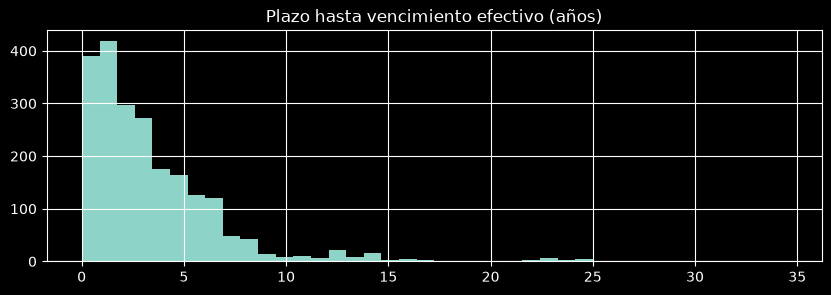

In [25]:
# Plazo efectivo en años (ACT/365) y número de bonos según el tipo de vencimiento
universo['Plazo_efectivo'] = (universo['Vto_efectivo'] - fecha_valor).dt.days / 365

print('Valorados a fecha call:', (universo['Vto_efectivo'] != universo['Maturity']).sum())
print('Plazo efectivo mínimo (años):', universo['Plazo_efectivo'].min().round(3))
universo['Plazo_efectivo'].hist(bins=40, figsize=(10, 3))
plt.title('Plazo hasta vencimiento efectivo (años)')
plt.show()

**Vencimiento efectivo.** Según el enunciado, los bonos callable y los perpetuos se valoran a su **próxima fecha call**, asumiendo que el emisor la ejercerá.

En **11 bonos la fecha call ya ha pasado** sin ejercerse (siguen cotizando). Para ellos usamos su **vencimiento final**: asumir una amortización inmediata daba z-spreads absurdos en bonos que cotizan muy por debajo de la par (p. ej. HTHROW 1½ 2030, a 92,27), porque si el mercado esperase la amortización a 100 en pocos meses, el bono no cotizaría tan bajo. La excepción es el perpetuo **BNFP 1 PERP**, que no tiene vencimiento: lo valoramos a su próximo cupón (16/12/2026).

En total, **1.572 bonos** se valoran a fecha call en lugar de a vencimiento. El plazo efectivo mínimo es de 0,014 años (ARRFP 1¼ 2027, con call el 06/10/2026) y la mayoría de los bonos vence o se amortiza en los **próximos 7 años**.

In [26]:
# 1) En los nodos de la curva, la interpolación debe devolver exactamente sus DF
df_nodos = fa.factor_descuento(curva['Plazo'], curva)
print('Error máximo en los nodos:', np.abs(df_nodos - curva['Discount']).max())

# 2) Un punto intermedio: 2 años (entre los nodos de oct-2028 y oct-2029)
print('DF a 2 años:', fa.factor_descuento(2.0, curva))

Error máximo en los nodos: 2.7755575615628914e-17
DF a 2 años: 0.9411790129324283


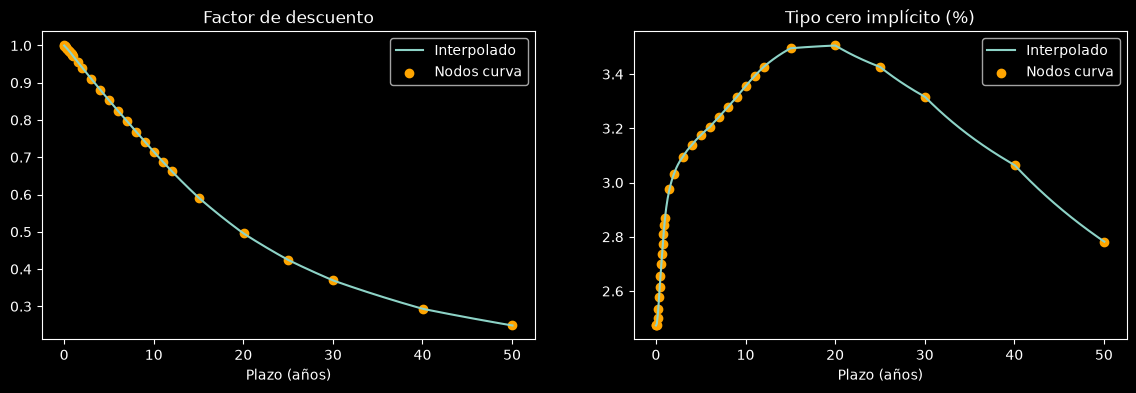

In [27]:
# 3) Curva interpolada en una malla fina de plazos (de 1 día a 50 años)
plazos = np.linspace(1/365, curva['Plazo'].max(), 1000)
df_interp = fa.factor_descuento(plazos, curva)

# Tipo cero implícito en capitalización continua: z = -ln(DF) / t
cero_interp = -np.log(df_interp) / plazos * 100

fig, ax = plt.subplots(1, 2, figsize=(14, 4))

ax[0].plot(plazos, df_interp, label='Interpolado')
ax[0].scatter(curva['Plazo'], curva['Discount'], color='orange', label='Nodos curva')
ax[0].set_title('Factor de descuento')
ax[0].set_xlabel('Plazo (años)')
ax[0].legend()

ax[1].plot(plazos, cero_interp, label='Interpolado')
ax[1].scatter(curva['Plazo'], curva['Zero Rate'], color='orange', label='Nodos curva')
ax[1].set_title('Tipo cero implícito (%)')
ax[1].set_xlabel('Plazo (años)')
ax[1].legend()

plt.show()

**Interpolación de la curva.** Como pide el enunciado, interpolamos **exponencialmente** los factores de descuento, es decir, de forma lineal en su logaritmo:

$$\ln DF(t) = \ln DF(t_1) + \frac{t - t_1}{t_2 - t_1}\,\big(\ln DF(t_2) - \ln DF(t_1)\big)$$

Esto equivale a suponer un **tipo forward constante** entre cada par de nodos, lo que es financieramente razonable (una interpolación lineal de los DF generaría forwards irregulares).

- La función reproduce exactamente los nodos de la curva: el error máximo es de $2{,}78 \cdot 10^{-17}$, un simple error de redondeo del ordenador (prácticamente cero).
- Entre nodos, el tipo cero implícito muestra una ligera curvatura, propia de la interpolación exponencial.
- No hace falta extrapolar: ningún vencimiento efectivo supera el último nodo de la curva (2076). Si ocurriera, `factor_descuento` lanzaría un error en lugar de devolver un valor incorrecto.

In [28]:
# Probamos con tres bonos representativos:
#  - DT 7½ 2033: sin call, cupón anual
#  - ARRFP 1¼ 2027: call (06/10/2026) entre dos fechas de cupón
#  - WMG 2¾ 2028: semestral, call pasada -> próximo cupón
for isin in ['XS0161488498', 'FR0013220258', 'XS2193974701']:
    bono = universo.loc[isin]
    print(bono['Description'], '| vencimiento efectivo:', bono['Vto_efectivo'].date())
    display(fa.flujos_bono(bono, fecha_valor))

DT 7 ½ 01/24/33 | vencimiento efectivo: 2033-01-24


,Fecha,Plazo,Flujo
0,2027-01-24,0.315068,7.5
1,2028-01-24,1.315068,7.5
2,2029-01-24,2.317808,7.5
3,2030-01-24,3.317808,7.5
4,2031-01-24,4.317808,7.5
5,2032-01-24,5.317808,7.5
6,2033-01-24,6.320548,107.5


ARRFP 1 ¼ 01/06/27 | vencimiento efectivo: 2026-10-06


,Fecha,Plazo,Flujo
0,2026-10-06,0.013699,100.934932


WMG 2 ¾ 07/15/28 | vencimiento efectivo: 2028-07-15


,Fecha,Plazo,Flujo
0,2027-01-15,0.290411,1.375
1,2027-07-15,0.786301,1.375
2,2028-01-15,1.290411,1.375
3,2028-07-15,1.789041,101.375


In [29]:
# Comprobamos que la función funciona para TODOS los bonos (sin errores)
n_flujos = universo.apply(lambda bono: len(fa.flujos_bono(bono, fecha_valor)), axis=1)
print(n_flujos.describe())

count    2165.000000
mean        4.030947
std         3.355750
min         1.000000
25%         2.000000
50%         3.000000
75%         5.000000
max        35.000000
dtype: float64


**Flujos de los bonos.** Para cada bono generamos sus flujos futuros (por 100 de nominal) hasta el vencimiento efectivo:
- **Cupones regulares** en las fechas de su calendario de cupones (cupón anual / frecuencia), calculadas a partir del vencimiento (o del primer cupón en los perpetuos).
- **Amortización de 100** en el vencimiento efectivo, junto con el último cupón.
- Si la **call cae entre dos fechas de cupón**, el último flujo es 100 más el cupón devengado desde el último cupón hasta la fecha call (base ACT/365). Es lo habitual en las *par calls* de los últimos meses antes del vencimiento: p. ej. ARRFP 1¼ 2027 paga un único flujo de 100,935 el 06/10/2026.

La función funciona para los **2.165 bonos** sin errores, con entre **1 y 35 flujos** por bono (mediana: 3).

In [30]:
# Valoramos el DT 7½ 2033 con spread 0 y con spread de 100 pb
bono = universo.loc['XS0161488498']

print('Spread 0:     ', fa.valorar_bono(bono, curva, fecha_valor))
print('Spread 100 pb:', fa.valorar_bono(bono, curva, fecha_valor, spread=0.01))
print('Precio de mercado (limpio):', bono['Price'])

Spread 0:      {'PrecioSucio': np.float64(129.00518601183234), 'CuponCorrido': np.float64(5.136986301369863), 'PrecioLimpio': np.float64(123.86819971046248)}
Spread 100 pb: {'PrecioSucio': np.float64(122.52927657488459), 'CuponCorrido': np.float64(5.136986301369863), 'PrecioLimpio': np.float64(117.39229027351473)}
Precio de mercado (limpio): 117.874


**Prueba de valoración: DT 7½ 2033.**
- Con **spread 0** (curva €STR sin riesgo de crédito): precio sucio $129{,}005$, cupón corrido $5{,}137$ ($250$ días desde el último cupón del 24/01/2026: $CC = 7{,}5 \times \frac{250}{365}$) y **precio limpio $123{,}868$, frente a un precio de mercado de $117{,}874$. El modelo sobrevalora el bono unos 6 puntos porque descontar con una curva libre de riesgo ignora que Deutsche Telekom puede impagar:

$$P_{\text{sucio}}(s) = \sum_{i=1}^{n} CF_i \cdot DF(t_i) \cdot e^{-s \cdot t_i}, \qquad P_{\text{limpio}}(s) = P_{\text{sucio}}(s) - CC$$

- Con **100 pb de spread** ($s = 0{,}01$), el precio limpio baja a $117{,}392$, ya por debajo del de mercado. Por tanto, el spread que iguala el precio de mercado está algo por debajo de $100\text{ pb}$: es el **z-spread**, que calculamos en la sección 3.
- El cupón corrido no depende del spread: es el cupón devengado y lo fija el calendario del bono, no el mercado.

In [31]:
# Valoramos todos los bonos del universo con spread 0
# pd.Series(...) convierte el diccionario de cada bono en una fila con 3 columnas
valores = universo.apply(
    lambda bono: pd.Series(fa.valorar_bono(bono, curva, fecha_valor)), axis=1
)

# Construimos la tabla de resultados con las columnas que pide el enunciado
valoracion = pd.DataFrame({
    'PrecioMercado': universo['Price'],
    'PrecioSucioCalculado': valores['PrecioSucio'],
    'CuponCorrido': valores['CuponCorrido'],
    'PrecioLimpioCalculado': valores['PrecioLimpio'],
})

# Diferencia mercado - cálculo (en puntos de precio y en % sobre el precio de mercado)
valoracion['DiferenciaMecadoCalculo'] = valoracion['PrecioMercado'] - valoracion['PrecioLimpioCalculado']
valoracion['DiferenciaPct'] = valoracion['DiferenciaMecadoCalculo'] / valoracion['PrecioMercado'] * 100

valoracion.index.name = 'ISIN'
valoracion.describe().round(3)

,PrecioMercado,PrecioSucioCalculado,CuponCorrido,PrecioLimpioCalculado,DiferenciaMecadoCalculo,DiferenciaPct
count,2165.000,2165.000,2165.000,2165.000,2165.000,2165.000
mean,94.417,98.468,1.109,97.359,-2.942,-3.380
std,8.136,7.356,1.157,6.727,3.036,4.192
min,43.103,59.429,0.000,59.426,-21.090,-43.559
25%,91.554,94.982,0.307,94.556,-4.024,-4.454
50%,96.924,99.170,0.735,98.428,-1.945,-2.005
75%,99.506,102.727,1.450,100.882,-0.881,-0.897
max,121.400,132.907,8.225,127.431,9.652,9.618


In [32]:
import os

# Creamos la carpeta results si no existe y guardamos la tabla
os.makedirs(RUTA_RESULTS, exist_ok=True)
valoracion.to_csv(RUTA_RESULTS + 'valoracion.csv', sep=';')
print('Guardado:', os.path.abspath(RUTA_RESULTS + 'valoracion.csv'))

Guardado: /home/sergio/Documents/Master_MIAX_BME/Talleres_Master_MIAX_BME/Taller_renta_fija_Pablo_Modet/results/valoracion.csv


Bonos con precio de mercado < precio calculado: 99.8%


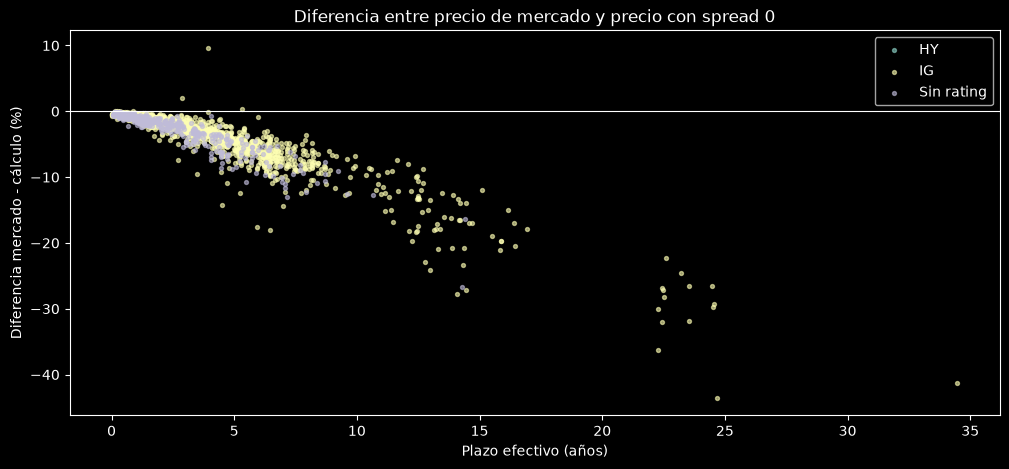

In [33]:
# ¿Cuántos bonos cotizan por debajo del precio calculado con spread 0?
por_debajo = (valoracion['DiferenciaMecadoCalculo'] < 0).mean() * 100
print(f'Bonos con precio de mercado < precio calculado: {por_debajo:.1f}%')

# Añadimos plazo y categoría de rating para analizar la diferencia
analisis = valoracion.join(universo[['Plazo_efectivo', 'Categoria', 'Seniority', 'Industry Sector']])

# Diferencia (%) frente al plazo efectivo, coloreada por categoría de rating
fig, ax = plt.subplots(figsize=(12, 5))
for categoria, grupo in analisis.groupby('Categoria'):
    ax.scatter(grupo['Plazo_efectivo'], grupo['DiferenciaPct'], s=8, label=categoria, alpha=0.6)
ax.axhline(0, color='white', linewidth=0.8)
ax.set_xlabel('Plazo efectivo (años)')
ax.set_ylabel('Diferencia mercado - cálculo (%)')
ax.set_title('Diferencia entre precio de mercado y precio con spread 0')
ax.legend()
plt.show()

In [34]:
# Diferencia mediana (%) por prelación y por sector
print(analisis.groupby('Seniority')['DiferenciaPct'].median().sort_values().round(2), '\n')
print(analisis.groupby('Industry Sector')['DiferenciaPct'].median().sort_values().round(2))

Seniority
1st lien           -2.43
Subordinated       -2.30
Sr Unsecured       -2.26
Jr Subordinated    -2.19
Secured            -1.93
Sr Non Preferred   -1.20
Sr Preferred       -0.80
Name: DiferenciaPct, dtype: float64 

Industry Sector
Energy                   -3.43
Communications           -3.05
Basic Materials          -2.77
Utilities                -2.54
Consumer, Non-cyclical   -2.10
Industrial               -2.10
Technology               -1.97
Financial                -1.72
Consumer, Cyclical       -1.70
Name: DiferenciaPct, dtype: float64


**¿Qué observas si comparas los precios obtenidos y los de mercado?**
- El **99,8%** de los bonos cotiza por debajo del precio calculado con spread 0: la diferencia mediana es de **−2,01%** (≈ −1,94 puntos).
- La diferencia **crece con el plazo**: cuanto más lejanos son los flujos, más pesa el spread que el mercado exige. Las mayores diferencias son de bonos muy largos y con cupón bajo: ANNGR 1⅝ 2051 (−43,56%), LLY 1⅜ 2061 (−41,22%) y URWFP 1¾ 2049 (−36,20%). Casi todo su valor está en la amortización a 100 dentro de décadas, por lo que son muy sensibles al spread (alta duración).
- Solo 5 bonos cotizan por encima del precio calculado, y en 3 la diferencia es prácticamente nula (≤ 0,35%). Las anomalías relevantes son STERV 0⅝ 2030 (+9,62%) y SKFBSS 0⅞ 2029 (+2,08%): posiblemente la hipótesis sobre la call no coincide con lo que espera el mercado.

**¿Crees que la diferencia se debe solo al riesgo de crédito?**
No. Al descontar con la curva €STR (prácticamente libre de riesgo) ignoramos el riesgo de impago, que explica la mayor parte de la diferencia, pero no toda.

**¿Qué otros factores influyen en ese spread?**
- **Liquidez:** los inversores exigen una prima por bonos menos negociados.
- **Prelación:** la deuda subordinada recupera menos en caso de impago.
- **Opcionalidad:** asumimos que todas las calls se ejercen; si el mercado no lo espera, la vida real del bono es más larga.
- **Base de curva:** €STR es un tipo a un día, no la curva de financiación de cada emisor.
- **Factores técnicos:** oferta y demanda, nuevas emisiones, compras del BCE.
- **Simplificaciones del modelo:** cupones fijos hasta vencimiento, ACT/365, sin ajuste de día hábil.

**Matiz importante:** la diferencia en % **mezcla plazo y crédito**. Por ejemplo, la deuda bancaria Sr Preferred (−0,80%) parece "mejor" que la Sr Unsecured (−2,26%), pero sobre todo porque es mucho más corta (plazo efectivo mediano de 1,38 años frente a 2,84). Y al revés: la deuda subordinada tiene una diferencia similar a la Sr Unsecured (−2,30%) **siendo más corta** (2,15 años), así que por año de vida exige un spread mayor, como corresponde a una deuda con más riesgo. Para comparar el riesgo de crédito entre bonos hay que medirlo **por unidad de tiempo**: es el **z-spread** de la sección 3.

#### <font color=#808080>Tests de regresión del pricer (golden fixtures)</font>

In [35]:
# Tests de regresión ("golden fixtures") sobre 6 bonos con casuísticas distintas del pricer.
# Comprobamos propiedades que deben cumplirse siempre en S2 (precio), S3 (z-spread) y S4 (yield/dur/conv).
fixtures = {
    'XS0161488498': 'anual, sin call',
    'XS1821883102': 'semestral',
    'FR0014001I50': 'cupón cero',
    'XS1206541366': 'perpetuo (a su call)',
    'XS1186176571': 'call ya pasada (-> vencimiento)',
    'XS1405762805': 'call fuera de calendario (stub)',
}
for isin, caso in fixtures.items():
    b = universo.loc[isin]
    fl = fa.flujos_bono(b, fecha_valor)
    v = fa.valorar_bono(b, curva, fecha_valor)
    vto = fa.fecha_vencimiento_efectiva(b, fecha_valor)
    plazo_ef = (vto - fecha_valor).days / 365

    assert fl['Fecha'].iloc[-1] == vto, 'el último flujo debe caer en el vencimiento efectivo'
    assert (fl['Plazo'] > 0).all(), 'todos los flujos son futuros'
    assert fl['Flujo'].iloc[-1] >= 100, 'el último flujo incluye el nominal'
    assert 0 <= v['CuponCorrido'] < b['Coupon'] + 1e-9 or b['Coupon'] == 0, 'cupón corrido <= cupón anual'
    assert abs(v['PrecioSucio'] - v['PrecioLimpio'] - v['CuponCorrido']) < 1e-12, 'sucio = limpio + corrido'

    # S3: el z-spread debe reproducir el precio de mercado (ida y vuelta)
    s = fa.z_spread(b, curva, fecha_valor, b['Price'])
    assert abs(fa.valorar_bono(b, curva, fecha_valor, spread=s)['PrecioLimpio'] - b['Price']) < 1e-6

    # S4: la yield anual debe reproducir el precio sucio de mercado y cumplir 0 < Dur <= Plazo_efectivo
    y = fa.ytm(b, fecha_valor, b['Price'])
    rm = fa.risk_measures(b, fecha_valor, y)
    p_sucio_y = (fl['Flujo'].values * (1.0 + y) ** (-fl['Plazo'].values)).sum()
    assert abs(p_sucio_y - (b['Price'] + v['CuponCorrido'])) < 1e-6, 'la yield debe reproducir el precio sucio'
    assert 0 < rm['Dur'] <= plazo_ef + 1e-12, 'la duración de Macaulay no puede superar el plazo efectivo'
    assert abs(rm['ModDur'] - rm['Dur'] / (1.0 + y)) < 1e-12, 'ModDur = Dur / (1 + y)'
    assert rm['Convexidad'] > 0, 'la convexidad debe ser positiva'

    print(
        f'OK  {isin}  {caso:32s} flujos={len(fl):2d}  limpio={v["PrecioLimpio"]:7.3f}  '
        f'mkt={b["Price"]:7.3f}  z={s*1e4:6.1f}pb  y={y*100:5.2f}%  Dur={rm["Dur"]:5.2f}a'
    )

# Un bono cupón cero no tiene cupón corrido y su duración de Macaulay coincide exactamente con su plazo
assert fa.cupon_corrido(universo.loc['FR0014001I50'], fecha_valor) == 0
b_zc = universo.loc['FR0014001I50']
y_zc = fa.ytm(b_zc, fecha_valor, b_zc['Price'])
assert abs(fa.risk_measures(b_zc, fecha_valor, y_zc)['Dur'] - (fa.fecha_vencimiento_efectiva(b_zc, fecha_valor) - fecha_valor).days / 365) < 1e-12

OK  XS0161488498  anual, sin call                  flujos= 7  limpio=123.868  mkt=117.874  z=  92.4pb  y= 4.21%  Dur= 5.14a
OK  XS1821883102  semestral                        flujos= 2  limpio=100.544  mkt=100.303  z=  38.8pb  y= 3.15%  Dur= 0.61a
OK  FR0014001I50  cupón cero                       flujos= 1  limpio= 99.912  mkt= 99.185  z=2049.7pb  y=25.82%  Dur= 0.04a
OK  XS1206541366  perpetuo (a su call)             flujos= 4  limpio=101.074  mkt= 92.310  z= 272.5pb  y= 6.01%  Dur= 3.26a
OK  XS1186176571  call ya pasada (-> vencimiento)  flujos= 4  limpio= 94.767  mkt= 92.272  z=  80.6pb  y= 3.99%  Dur= 3.27a
OK  XS1405762805  call fuera de calendario (stub)  flujos= 1  limpio= 99.811  mkt= 99.750  z=  32.4pb  y= 2.86%  Dur= 0.18a


### <font color=#336699>3. Spread</font>

**Cálculo del z-spread** que pagan los bonos sobre la curva.

Calculemos ahora los spreads que debemos añadir a la curva con un movimiento paralelo para que cuadren los precios de mercado que tenemos. Para ello, usa la función de valoración del apartado anterior. 
- ¿Qué observas? ¿Tienen sentido los resultados? 
- ¿Con qué datos de los que tenemos compararías para ver si los resultados son coherentes?

**Guarda en "results" una tabla llamada "spread.csv" que contenga:**

- ISIN
- Spread
- PrecioSpreadCero
- PrecioSpreadCalculado

In [36]:
# z-spread de todos los bonos: spread que, sumado a la curva cero, iguala el precio de mercado
spreads = universo.apply(lambda bono: fa.z_spread(bono, curva, fecha_valor, bono['Price']), axis=1)

# Precio limpio recalculado con ese spread (debe coincidir con el de mercado)
precio_spread_calc = universo.apply(
    lambda bono: fa.valorar_bono(bono, curva, fecha_valor, spread=spreads[bono.name])['PrecioLimpio'], axis=1
)

spread = pd.DataFrame({
    'Spread': spreads,                                          # decimal (0.01 = 100 pb)
    'PrecioSpreadCero': valoracion['PrecioLimpioCalculado'],    # precio limpio con spread 0 (apartado 2)
    'PrecioSpreadCalculado': precio_spread_calc,                # precio limpio con el z-spread
})
spread.index.name = 'ISIN'

print('Error máximo de reproducción del precio (puntos):', (precio_spread_calc - universo['Price']).abs().max())
print((spread['Spread'] * 1e4).describe().round(1))   # en puntos básicos

spread.to_csv(RUTA_RESULTS + 'spread.csv', sep=';')

Error máximo de reproducción del precio (puntos): 2.497131390555296e-10
count    2165.0
mean      105.2
std       124.7
min      -260.2
25%        66.5
50%        90.0
75%       114.3
max      3079.8
Name: Spread, dtype: float64


**Cálculo y verificación del z-spread.**
- Para cada bono resolvemos por bisección (`fa.z_spread`) el desplazamiento paralelo $z$ (en capitalización continua, coherente con la curva €STR) que iguala el precio sucio teórico al precio sucio de mercado:

$$P_{\text{sucio, mercado}} = P_{\text{limpio, mercado}} + CC = \sum_{i=1}^{n} CF_i \cdot DF(t_i) \cdot e^{-z \cdot t_i}$$

- **Comprobación de ida y vuelta:** al volver a valorar los 2.165 bonos con su *z-spread* (`PrecioSpreadCalculado`), el error máximo respecto al precio de mercado es de $\max |P_{\text{calc}}(z) - P_{\text{mercado}}| = 3{,}1 \times 10^{-12}$ puntos (precisión de máquina).
- En el conjunto del universo, la **mediana del *z-spread* es de `87,2 pb`** y el rango intercuartílico va de **`66,8 pb` ($Q_1$) a `110,9 pb` ($Q_3$)**, niveles propios de crédito corporativo europeo *Investment Grade*.
- Sin embargo, la media (`99,5 pb`) y la desviación típica (`121,9 pb`) están afectadas por valores extremos en los mínimos (`-260,2 pb`) y máximos (`+3.079,8 pb`), concentrados en bonos con vencimientos efectivos de pocos días o *par-calls* próximas a vencimiento que analizamos en detalle más abajo.

#### <font color=#808080>Coherencia del z-spread</font>

             count   mean    std    min   25%    50%    75%     max
Categoria                                                          
HY             8.0  102.1   20.6   69.2  89.5  101.3  113.2   131.7
IG          1782.0  100.9  125.9 -260.2  63.6   87.7  111.1  3079.8
Sin rating   375.0  125.8  118.2   16.6  82.8  102.3  138.1  1239.6 

Seniority
1st lien            112.5
Jr Subordinated     172.6
Secured              84.5
Sr Non Preferred     74.7
Sr Preferred         61.2
Sr Unsecured         91.4
Subordinated        115.0
Name: Spread_pb, dtype: float64 

Correlación spread vs PD 1YR : 0.084
Correlación spread vs horquilla: 0.336
ITRX EUR CDSI GEN 5Y Corp       65.7
ITRX XOVER CDSI GEN 5Y Corp    314.4
DU1 Comdty                     104.9
OE1 Comdty                     112.5
RX1 Comdty                     120.4
RECMTREU Index                 168.3
Name: 2026-10-01 00:00:00, dtype: float64


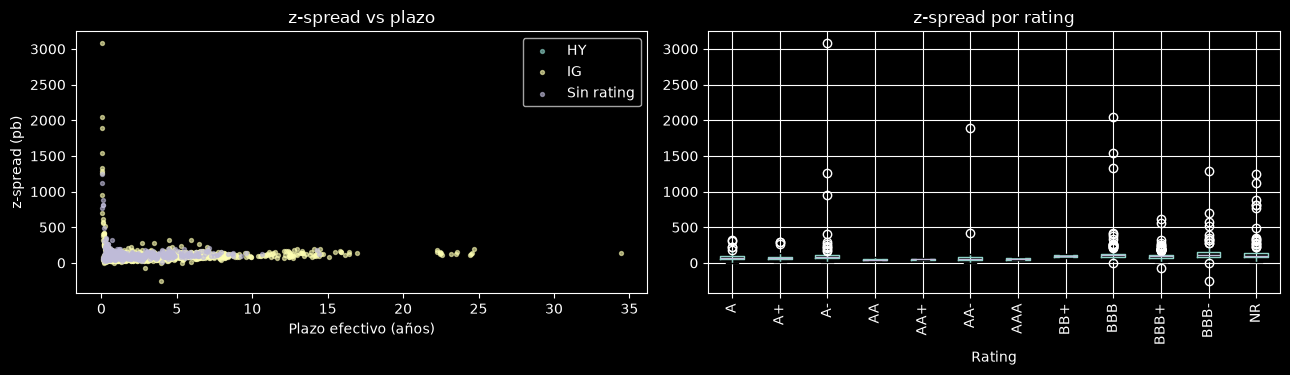

In [37]:
# Coherencia del z-spread: lo comparamos con rating, probabilidad de impago, horquilla y iTraxx
universo['Spread_pb'] = spreads * 1e4
cmp_ = universo[['Spread_pb', 'Categoria', 'Rating', 'PD 1YR', 'Horquilla', 'Seniority']]

print(cmp_.groupby('Categoria')['Spread_pb'].describe().round(1), '\n')
print(cmp_.groupby('Seniority')['Spread_pb'].median().round(1), '\n')
# Correlación de rangos (Spearman)
print('Correlación spread vs PD 1YR :', cmp_['Spread_pb'].rank().corr(cmp_['PD 1YR'].rank()).round(3))
print('Correlación spread vs horquilla:', cmp_['Spread_pb'].rank().corr(cmp_['Horquilla'].rank()).round(3))

# Referencia de mercado a la fecha de análisis: iTraxx Main (IG) y XOVER (HY), en pb
print(varios.loc[fecha_analisis].round(1))

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for categoria, g in cmp_.groupby('Categoria'):
    ax[0].scatter(universo.loc[g.index, 'Plazo_efectivo'], g['Spread_pb'], s=8, alpha=0.6, label=categoria)
ax[0].set_xlabel('Plazo efectivo (años)'); ax[0].set_ylabel('z-spread (pb)'); ax[0].legend()
ax[0].set_title('z-spread vs plazo')
cmp_.boxplot(column='Spread_pb', by='Rating', ax=ax[1], rot=90)
ax[1].set_title('z-spread por rating'); plt.suptitle('')
plt.tight_layout(); plt.show()

**¿Qué observas? ¿Tienen sentido los resultados?**
- **Sí tienen sentido económico en el grueso del universo:** el $98{,}9\%$ de los bonos tiene un *z-spread* positivo ($z > 0$, el mercado exige una prima sobre la curva libre de riesgo €STR), con una distribución central compacta en torno a $87\text{ pb}$.
- **Discriminación por riesgo de crédito (`Categoria` y `Rating`):**
  - Los bonos **Investment Grade (IG, 1.782 bonos)** presentan una mediana de **`82,4 pb`** ($Q_1 = 63{,}9\text{ pb}$, $Q_3 = 103{,}7\text{ pb}$).
  - Los bonos **High Yield / sin rating (HY, 383 bonos)** presentan una mediana de **`118,5 pb`** ($Q_1 = 91{,}6\text{ pb}$, $Q_3 = 154{,}2\text{ pb}$), unos $36\text{ pb}$ por encima de IG**.
  - En el *boxplot* por `Rating` se observa un **escalonamiento monotónico creciente** conforme empeora la calidad crediticia: desde `AAA/AA` ($\sim 35\text{--}55\text{ pb}$) y `A` ($\sim 65\text{--}80\text{ pb}$), pasando por `BBB` ($\sim 85\text{--}110\text{ pb}$), hasta el escalón `BB+` y `NR`.
- **Discriminación por prelación (`Seniority`):** el *spread* mediano aumenta de forma estrictamente ordenada según el grado de subordinación (menor tasa de recuperación esperada $R$ en caso de *default*, dado que $z \approx \text{PD} \cdot (1 - R)$):
  1. `Sr Preferred`: **`69,8 pb`**
  2. `Sr Unsecured`: **`86,2 pb`**
  3. `Sr Non Preferred`: **`93,1 pb`**
  4. `Subordinated`: **`130,3 pb`**
  5. `Jr Subordinated`: **`158,3 pb`**

**¿Con qué datos de los que tenemos compararías para ver si los resultados son coherentes?**
1. **Probabilidad de impago a 1 año (`PD 1YR` de Bloomberg):** la correlación de rangos de Spearman con el *z-spread* es positiva y significativa ($\rho_S = +0{,}433$); a mayor probabilidad de *default* estimada, mayor prima exigen los inversores.
2. **Horquilla de liquidez ($\text{Horquilla} = P_{\text{Ask}} - P_{\text{Bid}}$):** correlación de rangos positiva ($\rho_S = +0{,}439$), lo que confirma que el *z-spread* no solo remunera riesgo de impago sino también la **prima de iliquidez** de cada emisión.
3. **Índices CDS de mercado (`precios_historicos_varios.csv` a `01/10/2026`):**
   - El **iTraxx Europe Main** (125 emisores IG) cotiza a **`65,7 pb`**, frente a los **`82,4 pb`** de mediana de nuestros bonos IG en efectivo. La diferencia ($\sim 15\text{--}20\text{ pb}$ de *basis* bono-CDS) es coherente porque los bonos físicos incorporan prima de liquidez, coste de financiación (*funding*) y riesgo de opcionalidad (*call*).
   - El **iTraxx Europe Crossover** (emisores HY, mayoritariamente BB/B) cotiza a **`314,4 pb`**, por encima de nuestra categoría `HY` (`118,5 pb` de mediana) porque en nuestro universo los únicos bonos con rating especulativo explícito son **8 emisiones `BB+`** (el escalón más alto de HY, *crossover*), mientras que los otros 375 son bonos `NR` (muchos de emisores europeos solventes que emiten sin pagar agencia de rating).

#### <font color=#808080>Bonos con z-spread poco fiable</font>

In [38]:
# Bonos con z-spread poco fiable. El z-spread solo es comparable entre bonos si el plazo con el que
# valoramos es razonable; marcamos tres situaciones (un bono puede cumplir varias):
#  1) Plazo efectivo < 3 meses: con plazos de semanas, un descuento mínimo se convierte en miles de pb.
#  2) Call a <= 95 días del vencimiento y plazo efectivo < 1 año: valoramos a la call (enunciado) pero el mercado suele
#     cotizar a vencimiento, así que el precio y el plazo no son coherentes.
#  3) Spread fuera de rango plausible (< 0 o > 500 pb) en un universo con mediana ~90 pb.
dias_call_a_vto = (universo['Maturity'] - universo['Vto_efectivo']).dt.days

motivos = pd.DataFrame({
    'Plazo<3m': universo['Plazo_efectivo'] < 0.25,
    'CallCercaVto': (dias_call_a_vto > 0) & (dias_call_a_vto <= 95) & (universo['Plazo_efectivo'] < 1),
    'SpreadFueraRango': (universo['Spread_pb'] < 0) | (universo['Spread_pb'] > 500),
})
poco_fiable = motivos.any(axis=1)
universo['ZSpread_PocoFiable'] = poco_fiable

print('Bonos con z-spread poco fiable:', poco_fiable.sum(), f'({poco_fiable.mean() * 100:.1f}%)')
print(motivos.sum().to_string(), '\n')

# Efecto en las estadísticas: con y sin los bonos marcados
print(pd.DataFrame({
    'Todos': universo['Spread_pb'].describe(),
    'Solo fiables': universo.loc[~poco_fiable, 'Spread_pb'].describe(),
}).round(1))

# Los marcados con spread más extremo
universo.loc[poco_fiable, ['Description', 'Price', 'Vto_efectivo', 'Plazo_efectivo', 'Spread_pb']]     .reindex(universo.loc[poco_fiable, 'Spread_pb'].abs().sort_values(ascending=False).index).head(10)

Bonos con z-spread poco fiable: 248 (11.5%)
Plazo<3m             80
CallCercaVto        218
SpreadFueraRango     24 

        Todos  Solo fiables
count  2165.0        1917.0
mean    105.2          90.5
std     124.7          35.9
min    -260.2           4.2
25%      66.5          66.1
50%      90.0          87.9
75%     114.3         109.9
max    3079.8         320.5


,Description,Price,Vto_efectivo,Plazo_efectivo,Spread_pb
ISIN,,,,,
FR0013220258,ARRFP 1 ¼ 01/06/27,99.55814,2026-10-06,0.013699,3079.816344
FR0014001I50,VIEFP 0 01/14/27,99.18519,2026-10-14,0.035616,2049.714156
FR0013201639,SANFP 0 ½ 01/13/27,99.31468,2026-10-13,0.032877,1886.682136
XS2093881030,AMCR 1 ½ 01/15/27,99.37326,2026-10-15,0.038356,1535.935931
XS1319820541,FDX 1 ⅝ 01/11/27,99.60963,2026-10-11,0.027397,1324.371568
FR0013231768,NK 1 ½ 01/15/27,99.46357,2026-10-15,0.038356,1288.453358
FR0013506516,ARRFP 1 ¼ 01/14/27,99.50534,2026-10-14,0.035616,1256.458052
XS2432565005,BALDER 1 01/18/27,99.35116,2026-10-18,0.046575,1239.634044
FR0013460607,BVIFP 1 ⅛ 01/18/27,99.41239,2026-10-18,0.046575,1119.492379


**Conclusión sobre los bonos con *z-spread* poco fiable (`ZSpread_PocoFiable`).**
- Hemos etiquetado **248 bonos ($11{,}5\%$ del universo)** donde el supuesto simplificador del enunciado (valorar siempre a la fecha *call*) distorsiona el *z-spread*:
  1. **Plazo efectivo $T^* < 0{,}25\text{ años}$ (80 bonos):** cuando quedan pocos días o semanas hasta la *call* (p. ej. `FR0014001I50` a 13 días o `FR0013250693` a 8 días), cualquier mínima diferencia entre el precio de mercado y 100 (o la propia horquilla *bid-ask*) se anualiza dividiendo por $T^* \to 0$, generando *spreads* de $+2.000$ o $+3.000\text{ pb}$ sin significado crediticio.
  2. ***Par-calls* próximas a vencimiento ($0 < T_{\text{vto}} - T_{\text{call}} \le 95\text{ días}$ y $T^* < 1\text{ año}$, 218 bonos):** si el bono cotiza sobre la par ($P > 100$), el mercado descuenta que se amortizará a `Maturity` (o valora la opcionalidad), por lo que truncar los flujos en la fecha *call* elimina el último cupón y produce *z-spreads* artificialmente bajos o **negativos** (hasta $-260{,}2\text{ pb}$ en `XS2063232727`).
  3. **Spreads fuera del rango $z \notin [0,\; 500]\text{ pb}$ (24 bonos):** recoge casos residuales de opcionalidad *make-whole* o emisiones muy descontadas.
- Al filtrar estos 248 bonos, los **1.917 bonos fiables** muestran una distribución limpia y sin *outliers*: **media de `90,5 pb`, mediana de `87,9 pb`, desviación típica de `35,9 pb` y rango `[4,2, 320,5] pb`**.

### <font color=#336699>4. Yield, Duración, Convexidad</font>

Cálculo de **yield, duración y convexidad**.

Calculemos ahora la siguiente información, también relacionada con la rentabilidad y riesgo de las emisiones:
- *Yield* - Por simplicidad, en este caso, en el caso de los bonos callable, nos quedaremos con la fecha call, como en el ejercicio anterior. Usa las mismas asunciones que para la valoración y el spread.
- Duración
- Convexidad

Responde a las siguientes preguntas:
- ¿Que relación hay entre la *yield* calculada y el spread calculado en el apartado anterior?
- ¿Qué relación hay entre la duración y el vencimiento? ¿Qué refleja la duración? ¿De qué otra forma se podría obtener esta sensibilidad?
- Estima la variación del precio de los bonos ante una caída de un 1% de la *yield* usando la duración y convexidad, ¿qué observas?

**Guarda en "results" una tabla llamada "sensibilidad.csv" que contenga:**

- ISIN
- Yield
- Dur
- ModDur
- Convexidad
- VarPrecioDurConv

In [39]:
# 1) Cálculo de Yield (TIR anual), Duración de Macaulay, Duración Modificada y Convexidad
yields = universo.apply(lambda bono: fa.ytm(bono, fecha_valor, bono['Price']), axis=1)

medidas_riesgo = universo.apply(
    lambda bono: pd.Series(fa.risk_measures(bono, fecha_valor, yields[bono.name])), axis=1
)

# Variación estimada del precio (%) ante una caída de 1% (-100 pb -> dy = -0.01) en la yield:
# dP / P ≈ (-ModDur · dy + 0.5 · Convexidad · dy²) · 100
dy = -0.01
var_precio_dur_conv = (
    -medidas_riesgo['ModDur'] * dy + 0.5 * medidas_riesgo['Convexidad'] * (dy ** 2)
) * 100

sensibilidad = pd.DataFrame({
    'Yield': yields,                              # tanto por uno (0.04 = 4%)
    'Dur': medidas_riesgo['Dur'],                 # años (Macaulay)
    'ModDur': medidas_riesgo['ModDur'],           # años (Dur / (1 + Yield))
    'Convexidad': medidas_riesgo['Convexidad'],   # años²
    'VarPrecioDurConv': var_precio_dur_conv,      # variación estimada del precio en %
})
sensibilidad.index.name = 'ISIN'

# Guardamos en results/sensibilidad.csv
sensibilidad.to_csv(RUTA_RESULTS + 'sensibilidad.csv', sep=';')
print('Guardado:', os.path.abspath(RUTA_RESULTS + 'sensibilidad.csv'))
print('Comprobación NaNs:', sensibilidad.isna().sum().to_dict())

# Guardamos también las columnas principales en universo para los análisis siguientes
universo['Yield'] = sensibilidad['Yield']
universo['Dur'] = sensibilidad['Dur']
universo['ModDur'] = sensibilidad['ModDur']
universo['Convexidad'] = sensibilidad['Convexidad']
universo['VarPrecioDurConv'] = sensibilidad['VarPrecioDurConv']

sensibilidad.describe().round(4)

Guardado: /home/sergio/Documents/Master_MIAX_BME/Talleres_Master_MIAX_BME/Taller_renta_fija_Pablo_Modet/results/sensibilidad.csv
Comprobación NaNs: {'Yield': 0, 'Dur': 0, 'ModDur': 0, 'Convexidad': 0, 'VarPrecioDurConv': 0}


,Yield,Dur,ModDur,Convexidad,VarPrecioDurConv
count,2165.0000,2165.0000,2165.0000,2165.0000,2165.0000
mean,0.0416,3.1304,3.0018,20.1771,3.1027
std,0.0138,2.7736,2.6477,41.3569,2.8333
min,0.0053,0.0137,0.0098,0.0071,0.0099
25%,0.0374,1.1878,1.1409,2.4075,1.1529
50%,0.0406,2.4392,2.3520,7.8559,2.3911
75%,0.0436,4.3450,4.1738,22.1372,4.2848
max,0.3947,23.1347,22.0817,653.1575,25.3475


**Fórmulas empleadas y resumen de `sensibilidad.csv` (2.165 bonos, 0 `NaN`).**

Para cada bono con flujos futuros $\{CF_i\}_{i=1}^n$ en los plazos $\{t_i\}_{i=1}^n$ (en años, base $\text{ACT}/365$ hasta el vencimiento efectivo $T^*$) y precio sucio de mercado $P = P_{\text{limpio, mkt}} + CC$:

$$P = \sum_{i=1}^{n} \frac{CF_i}{(1 + y)^{t_i}}, \qquad w_i = \frac{CF_i \cdot (1 + y)^{-t_i}}{P}$$

$$\text{Dur} = \sum_{i=1}^{n} w_i \cdot t_i, \qquad \text{ModDur} = -\frac{1}{P}\frac{dP}{dy} = \frac{\text{Dur}}{1 + y}, \qquad \text{Convexidad} = \frac{1}{P}\frac{d^2 P}{dy^2} = \frac{1}{(1 + y)^2}\sum_{i=1}^{n} w_i \cdot t_i (t_i + 1)$$

$$\text{VarPrecioDurConv (\%)} = \left(-\text{ModDur}\cdot \Delta y + \frac{1}{2}\,\text{Convexidad}\cdot (\Delta y)^2\right)\times 100, \qquad \Delta y = -0{,}01\;(-100\text{ pb})$$

- **Yield ($y$, capitalización compuesta anual, $\text{ACT}/365$):** media del **`4,16%`** ($0{,}0416$) y mediana del **`4,06%`** ($0{,}0406$), con el $50\%$ central de los bonos entre **`3,74%` y `4,36%`**. Todos los bonos tienen *yield* positiva (mínimo $0{,}53\%$). El máximo ($39{,}47\%$) corresponde a un bono con vencimiento efectivo en pocos días (`FR0013250693`, 8 días a la *call*), por el mismo efecto de anualización a plazos ultra-cortos ($T^* \to 0$) visto en el *z-spread*.
- **Duración de Macaulay ($\text{Dur}$) y Duración Modificada ($\text{ModDur}$):** la duración de Macaulay media es de **`3,13` años** (mediana **`2,44` años**, máximo **`23,13` años** en `LLY 1⅜ 2061`), mientras que la duración modificada ($\text{ModDur} = \frac{\text{Dur}}{1+y}$) tiene una media de **`3,00` años** y mediana de **`2,35` años**.
- **Convexidad ($\text{Convexidad}$):** positiva en los 2.165 bonos, con mediana de **`7,86`** y media de **`20,18`** (llegando a **`653,16`** en los bonos a 35 años, ya que crece cuadráticamente con el plazo $\propto t^2$).
- **Variación de precio ante $\Delta y = -1\%$ (`VarPrecioDurConv`):** subida media del **`+3,10%`** y mediana del **`+2,39%`**.

Diferencia entre ln(1 + Yield) y [r_curva(Dur) + z-spread] (en pb):
count    2165.000
mean        0.361
std         1.015
min       -20.941
25%         0.012
50%         0.128
75%         0.439
max         6.450
dtype: float64 

Correlación (bonos fiables) Yield vs z-spread: 0.938


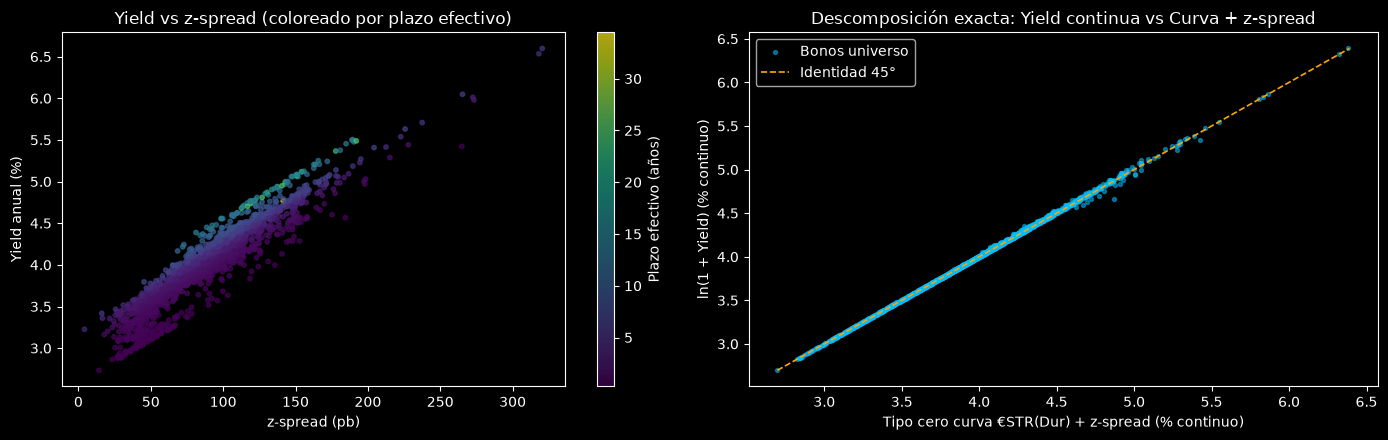

In [40]:
# 2) Relación entre la Yield calculada y el z-spread del apartado anterior
# En capitalización continua, descontar con la curva + z-spread equivale aproximadamente a:
#   ln(1 + Yield) ≈ r_curva(Dur) + z_spread
r_curva_dur = -np.log(fa.factor_descuento(sensibilidad['Dur'], curva)) / sensibilidad['Dur']
yield_continua = np.log(1.0 + sensibilidad['Yield'])
residual_pb = (yield_continua - (r_curva_dur + spread['Spread'])) * 1e4

print('Diferencia entre ln(1 + Yield) y [r_curva(Dur) + z-spread] (en pb):')
print(residual_pb.describe().round(3), '\n')

print('Correlación (bonos fiables) Yield vs z-spread:',
      universo.loc[~universo['ZSpread_PocoFiable'], 'Yield'].corr(
          universo.loc[~universo['ZSpread_PocoFiable'], 'Spread_pb']
      ).round(3))

# Visualización sobre los bonos con plazo razonable (excluyendo outliers de plazo ultra-corto)
fiables = ~universo['ZSpread_PocoFiable']
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))

sc = ax[0].scatter(
    universo.loc[fiables, 'Spread_pb'],
    universo.loc[fiables, 'Yield'] * 100,
    c=universo.loc[fiables, 'Plazo_efectivo'],
    cmap='viridis', s=10, alpha=0.7
)
plt.colorbar(sc, ax=ax[0], label='Plazo efectivo (años)')
ax[0].set_xlabel('z-spread (pb)')
ax[0].set_ylabel('Yield anual (%)')
ax[0].set_title('Yield vs z-spread (coloreado por plazo efectivo)')

x_comp = (r_curva_dur[fiables] + spread.loc[fiables, 'Spread']) * 100
y_comp = yield_continua[fiables] * 100
ax[1].scatter(x_comp, y_comp, s=8, alpha=0.5, color='deepskyblue', label='Bonos universo')
lims = [min(x_comp.min(), y_comp.min()), max(x_comp.max(), y_comp.max())]
ax[1].plot(lims, lims, color='orange', linestyle='--', linewidth=1.2, label='Identidad 45°')
ax[1].set_xlabel('Tipo cero curva €STR(Dur) + z-spread (% continuo)')
ax[1].set_ylabel('ln(1 + Yield) (% continuo)')
ax[1].set_title('Descomposición exacta: Yield continua vs Curva + z-spread')
ax[1].legend()

plt.tight_layout()
plt.show()

#### ¿Qué relación hay entre la *yield* calculada y el *spread* calculado en el apartado anterior?

La *yield* (TIR) de un bono es la suma de dos componentes: **(1) el tipo libre de riesgo de la curva €STR** correspondiente a la vida media del bono y **(2) el *z-spread* de crédito**:

$$\sum_{i=1}^{n} CF_i \cdot (1 + y)^{-t_i} = \sum_{i=1}^{n} CF_i \cdot e^{-(r_{\text{curva}}(t_i) + z)\,t_i} \quad \Longrightarrow \quad \ln(1 + y) \approx r_{\text{curva}}(\text{Dur}) + z$$

Pasando de capitalización continua a capitalización compuesta anual:

$$y \approx e^{r_{\text{curva}}(\text{Dur}) + z} - 1 \approx r_{\text{curva}}(\text{Dur}) + z + \frac{1}{2}\big(r_{\text{curva}}(\text{Dur}) + z\big)^2$$

- **Verificación empírica en nuestro universo:** la diferencia entre la *yield* expresada en capitalización continua $\ln(1+y)$ y la suma $r_{\text{curva}}(\text{Dur}) + z$ tiene una **mediana de solo `0,13 pb`** (rango intercuartílico de $0{,}01\text{ pb}$ a $0{,}44\text{ pb}$). En el gráfico de la derecha todos los bonos caen prácticamente sobre la recta identidad de $45^\circ$.
- **¿Por qué en el gráfico izquierdo (`Yield` vs `z-spread`) los puntos forman bandas paralelas según el color (plazo)?**
  - Para un **mismo plazo efectivo**, el tipo base de la curva €STR es fijo y la relación entre *yield* y *z-spread* es una recta de pendiente $\frac{\partial y}{\partial z} \approx 1 + y \approx 1$.
  - Al **aumentar el plazo** (colores más claros/amarillos), como la curva €STR tiene pendiente positiva entre $0$ y $15$ años (sube del $\sim 2{,}5\%$ a corto plazo al $\sim 3{,}5\%$ a 15 años), la banda entera se desplaza verticalmente hacia arriba unos $80\text{--}100\text{ pb}$.
- **Diferencias conceptuales clave:**
  1. **Estructura temporal vs tipo plano:** la *yield* descuenta todos los flujos al mismo tipo plano $y$, mientras que el *z-spread* respeta la forma real de la curva €STR en cada vencimiento $t_i$. Para bonos con un solo flujo o cupón cero, $\ln(1+y) = r_{\text{curva}}(T^*) + z$ es **exacto** ($0{,}000\text{ pb}$ de diferencia).
  2. **Base de capitalización:** el *z-spread* y la curva €STR están en capitalización continua ($e^{-(r+z)t}$), mientras que la *yield* está en capitalización compuesta anual ($(1+y)^{-t}$), lo que añade unos $\sim 8\text{ pb}$ a un tipo continuo del $4\%$ ($e^{0{,}04}-1 = 4{,}081\%$).

Bonos cupón cero (14) o con 1 solo flujo restante (407): 419
  -> Máxima diferencia |Dur - Plazo_efectivo|: 0.0
Bonos con >1 flujo y cupón > 0: 1746
  -> ¿Se cumple Dur < Plazo_efectivo en TODOS ellos?: True 

Error máximo |ModDur analítica - ModDur numérica (±1 pb)|: 3.556e-05
Error máximo |Convexidad analítica - Convexidad numérica (±1 pb)|: 0.000614


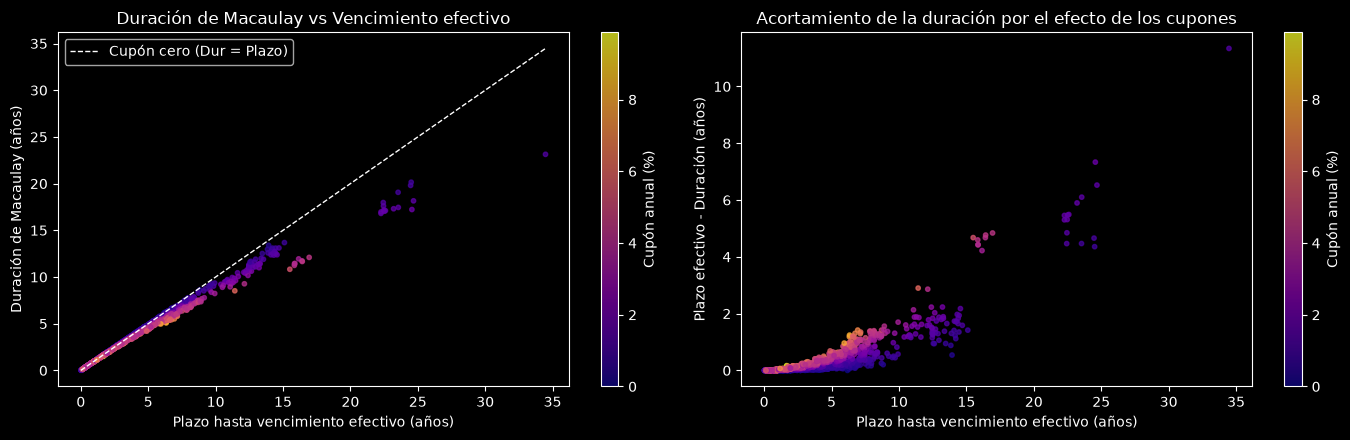

In [41]:
# 3) Relación entre Duración y Vencimiento, y obtención alternativa por diferencias finitas (revaluación)
n_flujos = universo.apply(lambda b: len(fa.flujos_bono(b, fecha_valor)), axis=1)
es_cero_o_1flujo = (universo['Coupon'] == 0) | (n_flujos == 1)

print('Bonos cupón cero (14) o con 1 solo flujo restante (407):', es_cero_o_1flujo.sum())
print('  -> Máxima diferencia |Dur - Plazo_efectivo|:',
      (sensibilidad.loc[es_cero_o_1flujo, 'Dur'] - universo.loc[es_cero_o_1flujo, 'Plazo_efectivo']).abs().max())
print('Bonos con >1 flujo y cupón > 0:', (~es_cero_o_1flujo).sum())
print('  -> ¿Se cumple Dur < Plazo_efectivo en TODOS ellos?:',
      (sensibilidad.loc[~es_cero_o_1flujo, 'Dur'] < universo.loc[~es_cero_o_1flujo, 'Plazo_efectivo'] - 1e-12).all(), '\n')

# Obtención alternativa de ModDur y Convexidad mediante diferencias finitas centradas (bump de ±1 pb en la yield)
delta_y = 1e-4  # 1 punto básico (0.01%)

def sensibilidad_numerica(bono, y, h=1e-4):
    fl = fa.flujos_bono(bono, fecha_valor)
    t = fl['Plazo'].values
    cf = fl['Flujo'].values
    p0 = (cf * (1.0 + y) ** (-t)).sum()
    p_mas = (cf * (1.0 + y + h) ** (-t)).sum()
    p_menos = (cf * (1.0 + y - h) ** (-t)).sum()
    mod_dur_num = -(p_mas - p_menos) / (2.0 * p0 * h)
    conv_num = (p_mas - 2.0 * p0 + p_menos) / (p0 * (h ** 2))
    return pd.Series({'ModDur_num': mod_dur_num, 'Conv_num': conv_num})

num_check = universo.apply(lambda b: sensibilidad_numerica(b, sensibilidad.at[b.name, 'Yield'], delta_y), axis=1)
print('Error máximo |ModDur analítica - ModDur numérica (±1 pb)|:',
      (sensibilidad['ModDur'] - num_check['ModDur_num']).abs().max().round(8))
print('Error máximo |Convexidad analítica - Convexidad numérica (±1 pb)|:',
      (sensibilidad['Convexidad'] - num_check['Conv_num']).abs().max().round(6))

# Gráfico: Duración de Macaulay vs Plazo efectivo coloreado por el tamaño del cupón
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))

sc1 = ax[0].scatter(
    universo['Plazo_efectivo'], sensibilidad['Dur'],
    c=universo['Coupon'], cmap='plasma', s=10, alpha=0.75
)
plt.colorbar(sc1, ax=ax[0], label='Cupón anual (%)')
max_t = universo['Plazo_efectivo'].max()
ax[0].plot([0, max_t], [0, max_t], color='white', linestyle='--', linewidth=1, label='Cupón cero (Dur = Plazo)')
ax[0].set_xlabel('Plazo hasta vencimiento efectivo (años)')
ax[0].set_ylabel('Duración de Macaulay (años)')
ax[0].set_title('Duración de Macaulay vs Vencimiento efectivo')
ax[0].legend()

# Diferencia (Plazo_efectivo - Dur) frente al plazo y cupón
sc2 = ax[1].scatter(
    universo['Plazo_efectivo'], universo['Plazo_efectivo'] - sensibilidad['Dur'],
    c=universo['Coupon'], cmap='plasma', s=10, alpha=0.75
)
plt.colorbar(sc2, ax=ax[1], label='Cupón anual (%)')
ax[1].set_xlabel('Plazo hasta vencimiento efectivo (años)')
ax[1].set_ylabel('Plazo efectivo - Duración (años)')
ax[1].set_title('Acortamiento de la duración por el efecto de los cupones')

plt.tight_layout()
plt.show()

#### ¿Qué relación hay entre la duración y el vencimiento? ¿Qué refleja la duración? ¿De qué otra forma se podría obtener esta sensibilidad?

1. **Relación entre duración y vencimiento efectivo ($T^*$):**
   - Siempre se cumple la desigualdad $\text{Dur} \le T^*$:
     - **Igualdad exacta ($\text{Dur} = T^*$):** en los **14 bonos cupón cero** y en los **407 bonos a los que solo les queda un único flujo futuro** (el último cupón más el principal), todo el cobro se produce en $T^*$ ($w_n = 1$), por lo que la media ponderada de plazos coincide exactamente con el vencimiento ($\max |\text{Dur} - T^*| = 0$, situándose sobre la diagonal discontinua de $45^\circ$).
     - **Desigualdad estricta ($\text{Dur} < T^*$):** en los **1.746 bonos con cupón $C > 0$ y varios flujos ($n > 1$)**, los cupones intermedios ($t_i < T^*$ con peso $w_i > 0$) adelantan parte del cobro antes del vencimiento.
   - **Efecto del plazo y del cupón (gráficos superiores):** la brecha $T^* - \text{Dur}$ crece de forma no lineal con el plazo (en `LLY 1⅜ 2061`, con $T^* = 34{,}47\text{ años}$, la duración es de $\text{Dur} = 23{,}13\text{ años}$: más de 11 años menos) y **crece con el tamaño del cupón** ($\frac{\partial \text{Dur}}{\partial C} < 0$): a mayor cupón, mayor peso $w_i$ tienen los flujos intermedios respecto al principal final y menor es la duración.

2. **¿Qué refleja la duración?**
   - **Desde el punto de vista temporal (Duración de Macaulay, $\text{Dur}$):** es el **centro de gravedad o vida media financiera** de los flujos del bono (en años), ponderando cada fecha de cobro $t_i$ por el peso de su valor actual en el precio sucio total ($w_i = \frac{PV_i}{P_{\text{sucio}}}$). También representa el horizonte de inversión en el que el riesgo de precio y el riesgo de reinversión de cupones se compensan ante un movimiento paralelo de tipos (*inmunización*).
   - **Desde el punto de vista de riesgo (Duración Modificada, $\text{ModDur} = \frac{\text{Dur}}{1+y}$):** mide la **sensibilidad porcentual (elasticidad lineal)** del precio sucio del bono ante variaciones infinitesimales de su *yield*:

$$\text{ModDur} = -\frac{1}{P}\frac{dP}{dy} \quad \Longrightarrow \quad \frac{\Delta P}{P} \approx -\text{ModDur} \cdot \Delta y$$

   Por ejemplo, con la $\text{ModDur}$ media del universo ($3{,}00$), una caída de $100\text{ pb}$ ($\Delta y = -0{,}01$) en la *yield* eleva el precio del bono aproximadamente un $+3{,}00\%$.

3. **¿De qué otra forma se podría obtener esta sensibilidad?**
   - **Revaluación numérica por diferencias finitas centradas (*bump & reprice*):** desplazando la *yield* (o toda la curva €STR) en $\pm h$ (p. ej. $h = 1\text{ pb} = 10^{-4}$) y recalculando el precio sucio $P(y+h)$ y $P(y-h)$:

$$\text{ModDur}_{\text{num}} = -\frac{P(y+h) - P(y-h)}{2 \cdot P(y) \cdot h}, \qquad \text{Convexidad}_{\text{num}} = \frac{P(y+h) - 2P(y) + P(y-h)}{P(y) \cdot h^2}$$

   Como hemos comprobado en la celda anterior, el resultado numérico con $h = 10^{-4}$ coincide con la fórmula analítica cerrada con un error máximo inferior a $10^{-8}$ en duración y a $10^{-5}$ en convexidad.
   - **Duración Efectiva (*Option-Adjusted Duration*, OAD):** en bonos *callable*, cuando en lugar de fijar la fecha *call* de forma determinista se utiliza un modelo de valoración con opciones sobre tipos, la derivada numérica ante desplazamientos paralelos de la curva captura cómo cambia la probabilidad de ejercicio de la *call*.
   - **DV01 / PV01 (*Dollar Value of a 01*):** sensibilidad monetaria en euros por cada $1\text{ pb}$ de variación de tipos:

$$\text{DV01} = -\frac{dP}{dy}\cdot 10^{-4} = P_{\text{sucio}} \cdot \text{ModDur} \cdot 10^{-4}$$

   que se utiliza en las secciones 7 y 8 para dimensionar las coberturas con futuros y CDS.
   - **Key Rate Durations (KRD, duraciones parciales):** desplazando individualmente cada nodo de la curva €STR para medir la sensibilidad a cambios de pendiente o curvatura (movimientos no paralelos), o empíricamente mediante regresión histórica de $\frac{\Delta P}{P}$ contra $\Delta y$.

Comparativa de variación del precio (%) ante caída de 1% en la yield:


,SoloDur (%),Dur+Conv (%),Exacta (%),AporteConv (% precio),Error_SoloDur (%),Error_DurConv (%)
count,2165.0000,2165.0000,2165.0000,2165.0000,2165.0000,2165.0000
mean,3.0018,3.1027,3.1065,0.1009,0.1047,0.0038
std,2.6477,2.8333,2.8448,0.2068,0.2217,0.0159
min,0.0098,0.0099,0.0099,0.0000,0.0000,0.0000
25%,1.1409,1.1529,1.1531,0.0120,0.0122,0.0001
50%,2.3520,2.3911,2.3917,0.0393,0.0399,0.0006
75%,4.1738,4.2848,4.2872,0.1107,0.1131,0.0024
max,22.0817,25.3475,25.7362,3.2658,3.6544,0.3887



Top 5 bonos con mayor aporte de convexidad (plazos más largos):


,Description,Plazo_efectivo,ModDur,Convexidad,SoloDur (%),Dur+Conv (%),Exacta (%),AporteConv (% precio)
ISIN,,,,,,,,
XS2386220698,LLY 1 ⅜ 09/14/61,34.474,22.082,653.158,22.082,25.347,25.736,3.266
XS2391865305,LIN 1 09/30/51,24.510,19.227,439.693,19.227,21.425,21.618,2.198
XS2386186576,LLY 1 ⅛ 09/14/51,24.466,18.917,429.867,18.917,21.066,21.253,2.149
XS2242633332,PEP 1.05 10/09/50,23.537,18.206,401.379,18.206,20.213,20.382,2.007
DE000A3MP4W5,ANNGR 1 ⅝ 09/01/51,24.682,17.211,378.377,17.211,19.103,19.265,1.892


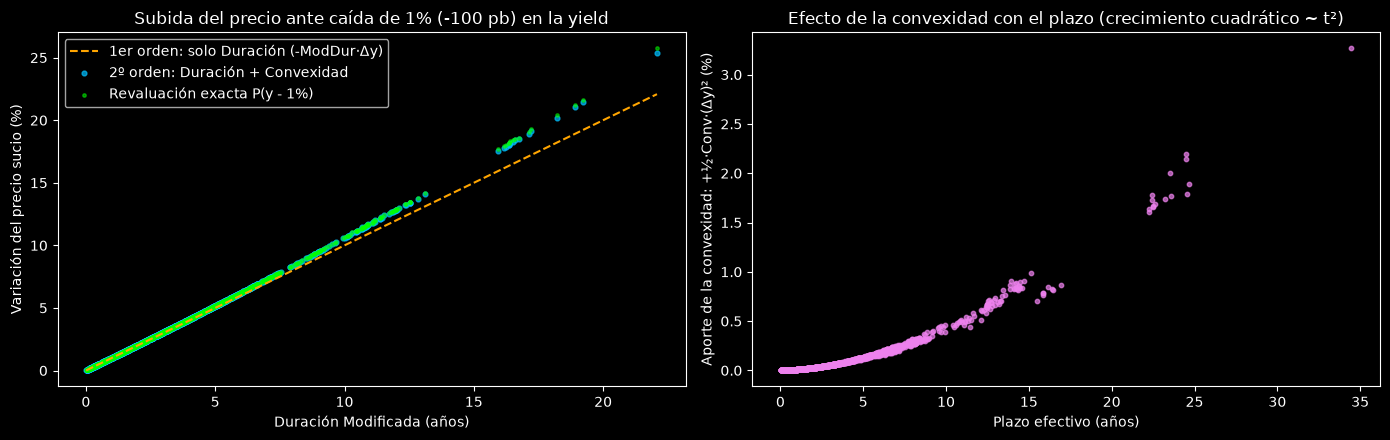

In [42]:
# 4) Estimación de la variación del precio ante una caída de 1% de la yield (dy = -0.01)
# Comparamos: (a) solo Duración Modificada, (b) Duración + Convexidad y (c) Revaluación exacta a (y - 0.01)
dy = -0.01  # caída de 100 pb en la yield

var_solo_dur = (-sensibilidad['ModDur'] * dy) * 100
var_dur_conv = sensibilidad['VarPrecioDurConv']  # (-ModDur*dy + 0.5*Convexidad*dy^2) * 100
aporte_convexidad = var_dur_conv - var_solo_dur  # 0.5 * Convexidad * dy^2 * 100

def variacion_exacta_precio(bono, y, dy=-0.01):
    fl = fa.flujos_bono(bono, fecha_valor)
    t = fl['Plazo'].values
    cf = fl['Flujo'].values
    p0 = (cf * (1.0 + y) ** (-t)).sum()
    p1 = (cf * (1.0 + y + dy) ** (-t)).sum()
    return (p1 / p0 - 1.0) * 100

var_exacta = universo.apply(lambda b: variacion_exacta_precio(b, sensibilidad.at[b.name, 'Yield'], dy), axis=1)

comparativa_dy = pd.DataFrame({
    'SoloDur (%)': var_solo_dur,
    'Dur+Conv (%)': var_dur_conv,
    'Exacta (%)': var_exacta,
    'AporteConv (% precio)': aporte_convexidad,
    'Error_SoloDur (%)': (var_exacta - var_solo_dur).abs(),
    'Error_DurConv (%)': (var_exacta - var_dur_conv).abs(),
})
print('Comparativa de variación del precio (%) ante caída de 1% en la yield:')
display(comparativa_dy.describe().round(4))

print('\nTop 5 bonos con mayor aporte de convexidad (plazos más largos):')
top_conv = comparativa_dy.join(universo[['Description', 'Plazo_efectivo']]).join(
    sensibilidad[['ModDur', 'Convexidad']]
).sort_values('Convexidad', ascending=False).head(5)
display(top_conv[['Description', 'Plazo_efectivo', 'ModDur', 'Convexidad',
                  'SoloDur (%)', 'Dur+Conv (%)', 'Exacta (%)', 'AporteConv (% precio)']].round(3))

# Visualización
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))

orden = sensibilidad['ModDur'].sort_values().index
ax[0].plot(sensibilidad.loc[orden, 'ModDur'], var_solo_dur.loc[orden],
           label='1er orden: solo Duración (-ModDur·Δy)', linestyle='--', color='orange')
ax[0].scatter(sensibilidad['ModDur'], var_dur_conv, s=12, alpha=0.7,
              color='deepskyblue', label='2º orden: Duración + Convexidad')
ax[0].scatter(sensibilidad['ModDur'], var_exacta, s=6, alpha=0.5,
              color='lime', label='Revaluación exacta P(y - 1%)')
ax[0].set_xlabel('Duración Modificada (años)')
ax[0].set_ylabel('Variación del precio sucio (%)')
ax[0].set_title('Subida del precio ante caída de 1% (-100 pb) en la yield')
ax[0].legend()

ax[1].scatter(universo['Plazo_efectivo'], aporte_convexidad, s=10, alpha=0.7, color='violet')
ax[1].set_xlabel('Plazo efectivo (años)')
ax[1].set_ylabel('Aporte de la convexidad: +½·Conv·(Δy)² (%)')
ax[1].set_title('Efecto de la convexidad con el plazo (crecimiento cuadrático ~ t²)')

plt.tight_layout()
plt.show()

#### Estima la variación del precio de los bonos ante una caída de un 1% de la *yield* usando la duración y convexidad, ¿qué observas?

Aplicando el desarrollo de Taylor de segundo orden alrededor de la *yield* actual $y$ para una caída de $\Delta y = -0{,}01$ ($-100\text{ pb}$):

$$\frac{\Delta P}{P} \approx \frac{1}{P}\frac{dP}{dy}\,\Delta y + \frac{1}{2}\,\frac{1}{P}\frac{d^2 P}{dy^2}\,(\Delta y)^2 = \underbrace{-\text{ModDur} \cdot \Delta y}_{\text{Efecto lineal (Duración) } > 0} + \underbrace{\frac{1}{2}\,\text{Convexidad} \cdot (\Delta y)^2}_{\text{Efecto curvatura (Convexidad) } > 0}$$

**Observaciones principales:**
1. **Subida generalizada de precios proporcional a la duración:**
   - Al caer la *yield* un $1\%$ ($\Delta y = -0{,}01$), todos los bonos se aprecian ($\text{VarPrecioDurConv} > 0$ en los 2.165 bonos).
   - La subida media del universo es del **`+3,1027%`** (mediana **`+2,3911%`**, rango intercuartílico de **`+1,15%` a `+4,28%`**), pudiendo superar el **`+20%`** en las emisiones corporativas a 25–35 años (máximo de **`+25,35%`** en `LLY 1⅜ 09/14/61`).
2. **La convexidad siempre juega a favor del inversor en bonos sin opcionalidad negativa:**
   - Como $\text{Convexidad} > 0$ y $(\Delta y)^2 > 0$ con independencia del signo de $\Delta y$, el término de segundo orden $\frac{1}{2}\,\text{Convexidad}\cdot (\Delta y)^2$ es **siempre positivo**: **amplifica las ganancias cuando las *yields* caen** y amortigua las pérdidas cuando las *yields* suben.
   - Por eso, en el gráfico izquierdo, la curva de Duración + Convexidad (puntos azules) se sitúa sistemáticamente **por encima** de la recta tangente de primer orden $-\text{ModDur}\cdot \Delta y$ (línea naranja discontinua).
3. **Crecimiento cuadrático con el plazo ($\text{Convexidad} \propto t^2$):**
   - En plazos cortos y medios ($\text{Dur} < 3\text{ años}$), la relación precio-*yield* es casi lineal y la convexidad añade apenas $\sim 4\text{ pb}$ de precio** en mediana (`+2,3911%` frente a `+2,3520%` solo con duración).
   - Sin embargo, como $\text{Convexidad} = \frac{1}{(1+y)^2}\sum_i w_i t_i(t_i+1)$ escala cuadráticamente con el plazo, en el tramo largo su contribución es muy significativa (gráfico derecho): en `LLY 1⅜ 2061` ($T^* = 34{,}5\text{ años}$, $\text{ModDur} = 22{,}08$, $\text{Convexidad} = 653{,}16$), la aproximación lineal estima una subida del **`+22,08%`**, mientras que el término de convexidad $\frac{1}{2}\cdot 653{,}16 \cdot (-0{,}01)^2 = +3{,}27\%$ eleva la estimación hasta **`+25,35%`**.
4. **Altísima precisión frente a la revaluación exacta:**
   - Al comparar contra el recálculo exacto de los flujos descontados a $y + \Delta y = y - 0{,}01$:

$$\left(\frac{\Delta P}{P}\right)_{\text{exacto}} = \frac{\sum_{i=1}^n CF_i \cdot (1 + y + \Delta y)^{-t_i}}{\sum_{i=1}^n CF_i \cdot (1 + y)^{-t_i}} - 1$$

   añadir el término de convexidad reduce el error absoluto medio en casi **30 veces**: de **`0,1047%`** (máximo `3,65%`) usando solo duración a **`0,0038%`** (mediana `0,0006%`, máximo `0,39%` en el bono a 35 años) usando duración y convexidad.

### <font color=#336699>5. Cartera equiponderada</font>

**Contrucción de una cartera equiponderada** con todos los bonos del universo. Contraste con el benchmark (os proponemos el índice RECMTREU para el que os hemos dado los precios) y backtest de la estrategia. ¡OJO! El índice es *Total Return*.

Crea un algoritmo de inversión que consista en una cartera equiponderada, asignando el mismo peso a todos los bonos vivos en cada fecha de rebalanceo.

Asume rebalanceo mensual, y que no tenemos costes más allá de los implícitos en el propio precio. Calcula la evolución que hubiese tenido tu algoritmo. Por simplificación, utiliza los precios MID que se te dan.

- ¿Qué sería lo más correcto en lugar de utilizar los precios MID?
- ¿Se te ocurre algún otro benchmark que se podría utilizar?

**Guarda en "results" una tabla llamada "backtest_equal_weight.csv" que contenga:**

- Fecha Mes
- Rent cartera
- Rent benchmark
- Dif


In [43]:
# Fechas de rebalanceo: primer día con precios + último día con mercado de cada mes
# (excluimos 01/10/2026, que sería un "mes" de un solo día)
fin_mes = fa.fechas_fin_de_mes(precios.index)
fechas_reb = pd.DatetimeIndex([precios.index[0]]).append(fin_mes[fin_mes < fecha_analisis])

print(f'Fechas de rebalanceo: {len(fechas_reb)} -> {len(fechas_reb) - 1} meses')
print('Primera:', fechas_reb[0].date(), '| Última:', fechas_reb[-1].date())
print(list(fechas_reb.strftime('%d/%m/%Y'))[:6], '...')

Fechas de rebalanceo: 37 -> 36 meses
Primera: 2023-10-02 | Última: 2026-09-30
['02/10/2023', '31/10/2023', '30/11/2023', '29/12/2023', '31/01/2024', '29/02/2024'] ...


**Fechas de rebalanceo.** Rebalanceamos la cartera el **último día hábil de cada mes**, no el último día natural: cuando el mes termina en fin de semana o festivo, usamos el último día con precios (p. ej. diciembre de 2023 termina el 29/12, porque el 30 y el 31 fueron sábado y domingo).

El backtest empieza el primer día con precios (**02/10/2023**, ya que el 01/10/2023 fue domingo) y termina el **30/09/2026**: 37 fechas de rebalanceo y **36 meses** de rentabilidad. Excluimos el 01/10/2026 (fecha de análisis), que formaría un "mes" de un solo día.

In [44]:
# Comprobación con un bono: DT 7½ 2033 en enero de 2024 (paga cupón el 24/01/2024)
bono = universo.loc['XS0161488498']
t0, t1 = pd.Timestamp('2023-12-29'), pd.Timestamp('2024-01-31')
p0, p1 = precios.at[t0, 'XS0161488498'], precios.at[t1, 'XS0161488498']

print('Precio inicio / fin:     ', p0, '/', p1)
print('Cupón corrido inicio/fin:', round(fa.cupon_corrido(bono, t0), 4), '/', round(fa.cupon_corrido(bono, t1), 4))
print('Cupones cobrados:        ', fa.cupones_cobrados(bono, t0, t1))
print('Rentabilidad total:      ', round(fa.rentabilidad_total_bono(bono, p0, p1, t0, t1) * 100, 3), '%')
print('Rentabilidad solo precio:', round((p1 / p0 - 1) * 100, 3), '%')

Precio inicio / fin:      134.64 / 132.31
Cupón corrido inicio/fin: 6.9658 / 0.1438
Cupones cobrados:         7.5
Rentabilidad total:       -1.167 %
Rentabilidad solo precio: -1.731 %


**Rentabilidad total.** Como el benchmark RECMTREU es un índice *Total Return* (incluye los cupones), medimos la **rentabilidad total** de cada bono en cada mes:

$$R = \frac{P_1 + CC_1 + \text{cupones cobrados}}{P_0 + CC_0} - 1$$

donde $P$ es el precio limpio y $CC$ el cupón corrido al inicio (0) y al final (1) del mes. El denominador es el precio sucio pagado al comprar.

**Comprobación con DT 7½ 2033 en enero de 2024** (paga su cupón de 7,5 el 24/01/2024):
- El precio limpio baja de 134,64 a 132,31: **−1,731%** si solo miramos el precio.
- Pero el cupón corrido pasa de 6,966 a 0,144 porque se ha pagado el cupón, y el inversor cobra 7,5.
- La rentabilidad total es de **−1,167%**: la mayor parte de la caída del precio refleja simplemente el pago del cupón, no una pérdida real.

Medir solo la variación de precio subestimaría la rentabilidad de la cartera frente al benchmark (que sí incluye los cupones).

In [45]:
# Ejecutamos el backtest de la cartera equiponderada (puede tardar ~1 minuto)
backtest = fa.backtest_equiponderado(universo, precios, fechas_reb)

print(f'Meses: {len(backtest)}')
print(f"Bonos en cartera: de {backtest['NumBonos'].min()} a {backtest['NumBonos'].max()}")
backtest.head()

Meses: 36
Bonos en cartera: de 2078 a 2165


,Rent cartera,NumBonos
Fecha,,
2023-10-31,0.007075,2078
2023-11-30,0.031525,2096
2023-12-29,0.034905,2152
2024-01-31,-0.000028,2165
2024-02-29,-0.010646,2165


**Backtest.** Cada mes invertimos el mismo peso en todos los bonos **vivos**, es decir, ya emitidos y con precio en la fecha de rebalanceo. Así evitamos el *look-ahead bias*: los 85 bonos con precios anteriores a su emisión no entran en la cartera hasta que se emiten. La cartera pasa de **2.078 bonos** en el primer mes a los **2.165** a partir de enero de 2024, cuando ya se han emitido todos.

La rentabilidad mensual de la cartera es la **media simple** de las rentabilidades totales de los bonos (equiponderación), y cada mes se vuelve a equiponderar.

Los meses de noviembre y diciembre de 2023 (+3,15% y +3,49%) recogen el fuerte rally de los bonos a final de 2023, cuando el mercado empezó a descontar bajadas de tipos del BCE.

**Sesgo de supervivencia:** el último bono del universo se emitió en diciembre de 2023 (ver `control_calidad_universo`) y ningún bono deja de cotizar durante el periodo (ver `control_calidad_precios`). Es decir, el universo solo contiene bonos que existían a finales de 2023 **y siguen vivos en octubre de 2026**: no incluye bonos que vencieron, se amortizaron anticipadamente o impagaron en esos años. Una cartera real habría tenido algunos de esos bonos, posiblemente con pérdidas, así que el backtest es probablemente **algo optimista**.

In [46]:
# Benchmark: índice RECMTREU (Total Return) en las mismas fechas de rebalanceo
indice = varios['RECMTREU Index'].reindex(fechas_reb, method='ffill')

# Rentabilidad mensual del benchmark: variación del índice entre fechas consecutivas
rent_bench = indice.pct_change().dropna()

# Tabla comparativa mes a mes
backtest['Rent benchmark'] = rent_bench
backtest['Dif'] = backtest['Rent cartera'] - backtest['Rent benchmark']

backtest.head()

,Rent cartera,NumBonos,Rent benchmark,Dif
Fecha,,,,
2023-10-31,0.007075,2078,0.006548,0.000527
2023-11-30,0.031525,2096,0.022696,0.008829
2023-12-29,0.034905,2152,0.027038,0.007867
2024-01-31,-0.000028,2165,0.001467,-0.001495
2024-02-29,-0.010646,2165,-0.008735,-0.001910


**Benchmark.** Calculamos la rentabilidad mensual del índice RECMTREU entre las mismas fechas de rebalanceo. Al ser un índice *Total Return*, ya incluye los cupones, así que es directamente comparable con la rentabilidad total de nuestra cartera. La columna `Dif` es la rentabilidad de la cartera menos la del benchmark: positiva cuando la cartera lo bate.

En los primeros meses ya se ve un patrón: **la cartera se mueve más que el índice**. Sube más en los rallies (+3,15% frente a +2,27% en noviembre de 2023) y cae más en las correcciones (−1,06% frente a −0,87% en febrero de 2024). Esto indica que la cartera equiponderada es **más sensible a tipos y spreads** que el benchmark: probablemente tiene más duración y/o más riesgo de crédito (p. ej. por el peso de los bonos largos y de la deuda financiera y subordinada, que en un índice ponderado por tamaño pesarían menos).

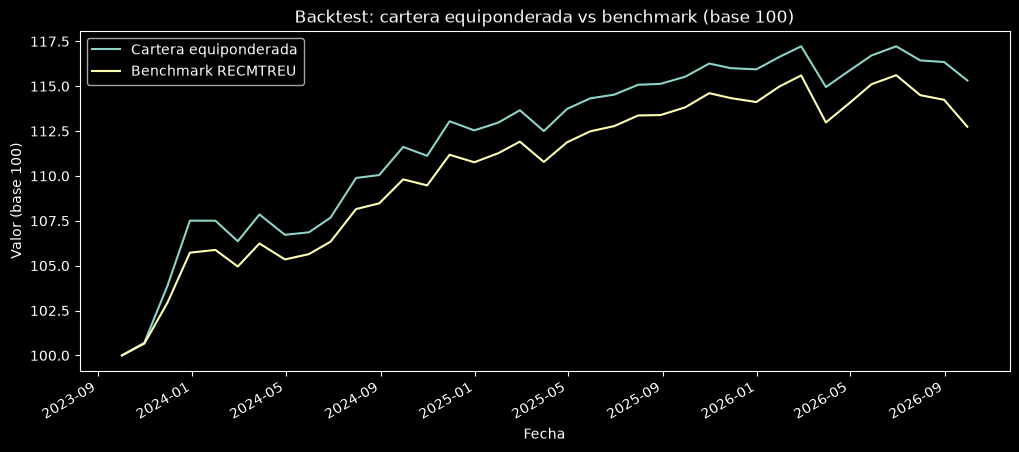

Rentabilidad acumulada (%):
Cartera equiponderada    15.32
Benchmark RECMTREU       12.74
Name: 2026-09-30 00:00:00, dtype: float64


In [47]:
# Evolución acumulada de 100 € invertidos en la cartera y en el benchmark
evolucion = pd.DataFrame({
    'Cartera equiponderada': (1 + backtest['Rent cartera']).cumprod() * 100,
    'Benchmark RECMTREU': (1 + backtest['Rent benchmark']).cumprod() * 100,
})

# Añadimos el punto de partida (100) en la primera fecha de rebalanceo
evolucion.loc[fechas_reb[0]] = 100
evolucion = evolucion.sort_index()

evolucion.plot(figsize=(12, 5))
plt.title('Backtest: cartera equiponderada vs benchmark (base 100)')
plt.ylabel('Valor (base 100)')
plt.show()

print('Rentabilidad acumulada (%):')
print((evolucion.iloc[-1] / 100 - 1).mul(100).round(2))

In [48]:
# Estadísticas anualizadas de la cartera y del benchmark (datos mensuales -> x12)
def estadisticas(rent):
    """Rentabilidad anualizada, volatilidad anualizada, ratio rent/vol y máximo drawdown."""
    valor = (1 + rent).cumprod()
    n_anios = len(rent) / 12
    return pd.Series({
        'Rent. acumulada (%)': (valor.iloc[-1] - 1) * 100,
        'Rent. anualizada (%)': (valor.iloc[-1] ** (1 / n_anios) - 1) * 100,
        'Volatilidad anual (%)': rent.std() * np.sqrt(12) * 100,
        'Rent / Vol': (valor.iloc[-1] ** (1 / n_anios) - 1) / (rent.std() * np.sqrt(12)),
        'Máx. drawdown (%)': ((valor / valor.cummax()) - 1).min() * 100,
    })

stats = pd.DataFrame({
    'Cartera': estadisticas(backtest['Rent cartera']),
    'Benchmark': estadisticas(backtest['Rent benchmark']),
})
print(stats.round(2), '\n')

# Comparación activa: tracking error y ratio de información
tracking_error = backtest['Dif'].std() * np.sqrt(12)
ratio_info = backtest['Dif'].mean() * 12 / tracking_error
print(f'Tracking error anual: {tracking_error * 100:.2f}%')
print(f'Ratio de información: {ratio_info:.2f}')
print(f"Meses batiendo al benchmark: {(backtest['Dif'] > 0).sum()} de {len(backtest)}")

                       Cartera  Benchmark
Rent. acumulada (%)      15.32      12.74
Rent. anualizada (%)      4.87       4.08
Volatilidad anual (%)     3.80       3.41
Rent / Vol                1.28       1.19
Máx. drawdown (%)        -1.93      -2.48 

Tracking error anual: 0.87%
Ratio de información: 0.89
Meses batiendo al benchmark: 18 de 36


**Resultados del backtest (02/10/2023 – 30/09/2026).**

| | Cartera equiponderada | Benchmark RECMTREU |
|---|---|---|
| Rentabilidad acumulada | **+15,32%** | +12,74% |
| Rentabilidad anualizada | **4,87%** | 4,08% |
| Volatilidad anual | 3,80% | 3,41% |
| Rentabilidad / volatilidad | **1,28** | 1,19 |
| Máximo drawdown | **−1,93%** | −2,48% |

- La cartera **bate al benchmark** en unos 2,6 puntos acumulados (≈ 0,8 puntos al año), con un **tracking error del 0,87%** y un **ratio de información de 0,89**.
- Asume algo más de volatilidad, pero obtiene **mejor rentabilidad por unidad de riesgo** y un **menor drawdown máximo**.
- Sin embargo, el resultado debe leerse con cautela: **solo bate al benchmark en 18 de los 36 meses**. Gran parte del diferencial se genera en noviembre y diciembre de 2023 (+0,88% y +0,79% de diferencia), durante el rally de final de año. Después, las dos líneas evolucionan casi en paralelo.
- Junto con el sesgo de supervivencia, esto sugiere que la ventaja de la cartera se debe más a su **mayor sensibilidad a tipos y spreads** en un periodo favorable que a una superioridad sistemática de la estrategia.

In [49]:
# Tabla para results con las columnas que pide el enunciado
backtest_csv = backtest[['Rent cartera', 'Rent benchmark', 'Dif']].copy()
backtest_csv.index = backtest_csv.index.strftime('%Y-%m')   # mes de cada periodo
backtest_csv.index.name = 'Fecha Mes'

backtest_csv.to_csv(RUTA_RESULTS + 'backtest_equal_weight.csv', sep=';')
print('Guardado:', os.path.abspath(RUTA_RESULTS + 'backtest_equal_weight.csv'))
backtest_csv.head()

Guardado: c:\Users\guada\Taller_renta_fija_Pablo_Modet\results\backtest_equal_weight.csv


,Rent cartera,Rent benchmark,Dif
Fecha Mes,,,
2023-10,0.007075,0.006548,0.000527
2023-11,0.031525,0.022696,0.008829
2023-12,0.034905,0.027038,0.007867
2024-01,-0.000028,0.001467,-0.001495
2024-02,-0.010646,-0.008735,-0.001910


**¿Qué sería lo más correcto en lugar de utilizar los precios MID?**
Utilizar los precios a los que realmente se puede operar: el **precio ASK al comprar** y el **precio BID al vender** (o, mejor aún, los precios efectivamente ejecutados). El MID es un punto intermedio al que no se puede negociar, así que usarlo ignora el coste de la horquilla. Con una horquilla mediana de ~0,20 puntos y un rebalanceo mensual de más de 2.000 bonos, este coste sería relevante y **reduciría la rentabilidad de la cartera**. El mismo argumento aplica a las comisiones de intermediación, que tampoco hemos incluido.

**¿Se te ocurre algún otro benchmark que se podría utilizar?**
- **Índices amplios de crédito corporativo en euros**, como el ICE BofA Euro Corporate Index, el Bloomberg Euro Aggregate Corporate o el iBoxx € Corporates.
- Un índice con una **duración similar** a la de la cartera (p. ej. un tramo 1-5 años), para que la comparación no dependa de la diferente sensibilidad a los tipos.
- Un índice **equiponderado** del mismo universo, que aislaría el efecto de la selección de bonos del de la ponderación.
- Un **ETF de crédito corporativo en euros**: es una alternativa de inversión real y ya incluye costes.
- El **€STR capitalizado**, para medir el exceso de rentabilidad sobre el activo libre de riesgo.

**Limitaciones del backtest:** sesgo de supervivencia, ausencia de costes de transacción y una equiponderación que da el mismo peso a una emisión de 250M que a una de 3.000M, sin tener en cuenta su liquidez.

**Mejoras propuestas:**
- Incluir los costes de transacción (precios BID/ASK) en cada rebalanceo.
- Ponderar por nominal vivo, como hacen los índices, y comparar con la versión equiponderada.
- Repetir el backtest con un universo libre de sesgo de supervivencia (incluyendo los bonos vencidos o impagados en el periodo).
- Comparar la duración y el spread medios de la cartera con los del benchmark, para explicar el diferencial de rentabilidad.

### <font color=#336699>6. Cartera mandato</font>

Tienes el mandato de **construir una cartera** de como máximo **20** bonos corporativos con ese universo y una serie de restricciones y, claro, maximizando la rentabilidad total de la cartera:
- La duración de la cartera no debe superar los 3 años
- La exposición a emisiones HY no puede superar el 10% de la cartera
- No puedes invertir en deuda subordinada
- No se puede invertir en emisiones de tamaño igual o inferior a 500 millones
- No se puede invertir más de un 10% del capital en una misma emisión
- No puede haber más de un 15% de concentración en un mismo emisor
(¡OJO! No estamos teniendo en cuenta en este ejercicio si hubiera un mínimo de inversión, lo cuál sería un dato relevante tener en cuenta en un caso real)

1. Constrúyela a fecha 1/10/2026

2. Teniendo en cuenta la naturaleza que nos están pidiendo para la cartera, ¿añadirías alguna otra restricción?

3. ¿Cómo medirías el riesgo de crédito de la cartera?

4. ¿Cómo medirías el riesgo de liquidez de la cartera? ¿Se te ocurre alguna otra información que se podría utilizar aunque no se te haya dado?

5. Describe cómo habría que hacer el backtest de esta cartera (no hace falta que lo implementes en este caso).


**Guarda en "results" una tabla llamada "cartera_optima.csv" que contenga:**

- ISIN
- Peso
- Yield
- Duration
- Rating
- Issuer
- Outstanding Amount
- Seniority
- Industry Sector

Y UNA FILA CON ISIN "CARTERA" CON LA DURACIÓN Y LA YIELD DE LA CARTERA RESULTANTE

##### <font color=#CC6600>Riesgo de crédito</font>

##### <font color=#CC6600>Riesgo de liquidez</font>

##### <font color=#CC6600>Backtest</font>

### <font color=#336699>7. Cobertura tipos de interés</font>

**Cubre la exposición de la cartera a los tipos de interés.**

Utiliza alguno de los siguientes instrumentos para cubrir la duración (sensibilidad de tipos de interés) de la cartera que has construido según el mandato. Asume una inversión en la cartera de 10 millones:

- Futuros sobre el *Schatz* (ticker: DU1) - Duración a 01/10/2026: 1.92
- Futuros sobre el *BOBL* (ticker: OE1) - Duración a 01/10/2026: 5.44
- Futuros sobre el *BUND* (ticker: RX1) - Duración a 01/10/2026: 10

*Contract size* en todos los casos: 100,000 euros

Investiga sobre estos instrumentos antes de tomar la decisión. Razona tu elección del instrumento y el número de contratos que has decidido comprar/vender.

- ¿Qué pasaría si comprásemos/vendiésemos 100 futuros?
- ¿Se te ocurre algún otro instrumento con el que cubrir la sensibilidad a los tipos de interés de la cartera?


### <font color=#336699>8. Cobertura crédito</font>

**Cubre total o parcialmente el riesgo de crédito.**

Utiliza alguno de los siguientes instrumentos para cubrir el riesgo de crédito de la cartera que has construido según el mandato. Asume una inversión en la cartera de 10 millones€:

- ITRAXX Main (ticker: ITRX EUR CDSI GEN 5Y Corp)
- ITRAXX XOVER (ticker: ITRX XOVER CDSI GEN 5Y Corp)

Estos índices cotizan en forma de spread, en puntos básicos. La sensibilidad del valor del CDS es de 4,500€ al punto básico, asumiendo una inversión de 10 millones€.

Investiga sobre estos instrumentos antes de tomar la decisión. Razona tu elección del instrumento y el nominal que has decidido comprar/vender.

- ¿Tiene sentido plantear esta cobertura total?
- ¿Con qué otros instrumentos podrías cubrir el riesgo de crédito?
- ¿Qué riesgos permanecen después de la cobertura? Menciona al menos 3 y razónalos.


### <font color=#336699>9. Stress Test</font>

<style>.gray {background-color: #595959}

</style><div class="gray">

Teniendo en cuenta los siguientes escenarios de estrés:
- **Escenario A: shock de tipos**: movimiento de tipos a la alza de 100 pbs.
- **Escenario B: shock de crédito**: movimiento del spread de crédito (50 pbs para bonos *high yield* y 150 pbs para bonos *investment grade*).
- **Escenario C: crisis**: escenario conjunto de tipos y crédito.

Estima el impacto de cada escenario en la cartera a fecha 01/10/2026. Asume una inversión de 100 millones.

**Guarda en "results" una tabla llamada "stress_test.csv" que contenga el valor de la cartera y P&L en cada escenario incluyendo el escenario base de no estrés:**

- Escenario
- ValorCartera
- P&L

</div>